# Grad-CAM ทั้ง 9 โมเดล (รันทีเดียวทั้งไฟล์)

In [1]:
import os, re, sys, json, time, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from scipy.ndimage import zoom
from IPython.display import display
warnings.filterwarnings("ignore")

# ---------------- ตั้งค่า (แก้ให้ตรงกับเครื่อง) ----------------
SHARED_DIR = "/home/jovyan/Alzheimer's/src/00-shared"                       # split.json / processing_lock.py / locked_cache
RUNS_ROOT = "."                                                              # โฟลเดอร์ที่มี runs_* (ค่าเริ่มต้น = โฟลเดอร์ของโน้ตบุ๊กนี้)
A_OUT_DIR = "/home/jovyan/Alzheimer's/src/01-data-review/A_check_output"    # ผลจากโน้ตบุ๊กข้อ A (ต้องมี template_to_T88.tfm)
OUT_DIR = "gradcam_output"
DEFS_DIR = "gradcam_defs"                                                    # โค้ดโมเดลที่คัดลอกมาจากโน้ตบุ๊กทดสอบ (เขียนให้เอง)
SEEDS = [1334, 42, 2026, 7, 2002]
GROUP_KEYS = None            # None = ทั้ง 9 โมเดล หรือใส่เช่น ["R18_3D", "R50_3D"]
RECOMPUTE = False            # False = ข้ามโมเดลที่คำนวณเสร็จแล้ว
SAVE_SUBJECT_MAPS = False    # True = เก็บแผนที่รายคน (ไฟล์ใหญ่ หลายร้อย MB ต่อโมเดล 3D)
MAX_SUBJECTS = None          # None = ทั้ง 36 คน (ตัวเลขน้อยกว่านี้ใช้ทดสอบโค้ดเท่านั้น)
BEST_FLIPS, BEST_SWAP = (True, False, False), False                         # ทิศทางแกนที่ไฟล์ A เลือกไว้ (ดูใน A_report.txt)
MIN_ROI_PIXELS = {"3D": 50, "plane": 20}                                     # บริเวณที่เห็นน้อยกว่านี้ไม่คำนวณอัตราโฟกัส
PRIMARY_LAYERS = ("layer3", "last_conv")

NB_DIR = os.getcwd()
RUNS_ROOT = os.path.abspath(RUNS_ROOT); OUT_DIR = os.path.abspath(OUT_DIR); DEFS_DIR = os.path.abspath(DEFS_DIR)
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(DEFS_DIR, exist_ok=True)
sys.path.insert(0, SHARED_DIR)
import processing_lock as PL
with open(os.path.join(SHARED_DIR, "split.json")) as f:
    _split = json.load(f)
TEST_IDS = [str(s).zfill(4) for s in _split["test"]]
if MAX_SUBJECTS:
    TEST_IDS = TEST_IDS[:MAX_SUBJECTS]
LABELS = {str(k).zfill(4): v for k, v in _split["labels"].items()}
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(PL.describe()); print("device:", device, "| คนในชุดทดสอบ:", len(TEST_IDS), "| โฟลเดอร์ผลรัน:", RUNS_ROOT)

GROUPS = [{'key': 'R18_2D', 'title': 'ResNet18 2D', 'src': 'Resnet18_2D.ipynb', 'exp_dir': 'runs_grid_2D', 'level': 'control', 'kind': 'dict'}, {'key': 'R18_25D', 'title': 'ResNet18 2.5D', 'src': 'Resnet18_25D.ipynb', 'exp_dir': 'runs_grid_25D', 'level': 'lr0.0001_adam0.0001_do0.3_ls0.2', 'kind': 'dict'}, {'key': 'R18_3D', 'title': 'ResNet18 3D', 'src': 'Resnet18_3D.ipynb', 'exp_dir': 'runs_resnet18_3D', 'level': 'stem_5', 'kind': '3d'}, {'key': 'R50_2D', 'title': 'ResNet50 2D', 'src': 'Resnet50_2D.ipynb', 'exp_dir': 'runs_grid50_2D', 'level': 'control', 'kind': 'dict'}, {'key': 'R50_25D', 'title': 'ResNet50 2.5D', 'src': 'Resnet50_25D.ipynb', 'exp_dir': 'runs_grid50_25D', 'level': 'control', 'kind': 'dict'}, {'key': 'R50_3D', 'title': 'ResNet50 3D', 'src': 'Resnet50_3D.ipynb', 'exp_dir': 'runs_resnet50_3D', 'level': 'stem_7', 'kind': '3d'}, {'key': 'BASE_2D', 'title': 'Baseline CNN 2D', 'src': 'Baseline_CNN_2D.ipynb', 'exp_dir': 'runs_baseline_2D', 'name': 'k5_b8', 'kind': 'base'}, {'key': 'BASE_25D', 'title': 'Baseline CNN 2.5D', 'src': 'Baseline_CNN_25D.ipynb', 'exp_dir': 'runs_baseline_25D', 'name': 'kernel_5', 'kind': 'base'}, {'key': 'BASE_3D', 'title': 'Baseline CNN 3D', 'src': 'Baseline_CNN_3D.ipynb', 'exp_dir': 'runs_baseline_3D', 'name': 'bn', 'kind': 'base'}]
if GROUP_KEYS:
    GROUPS = [g for g in GROUPS if g["key"] in GROUP_KEYS]
print("โมเดลที่จะทำ:", [g["key"] for g in GROUPS])


processing_lock v1 | hash 22275bfd6b | target (128, 128, 96) | clip p1-99 | order 1 | center (sag,cor,axi) = (64, 64, 48)
device: cuda | คนในชุดทดสอบ: 36 | โฟลเดอร์ผลรัน: /home/jovyan/Alzheimer's/src/Model/2D/Resnet18
โมเดลที่จะทำ: ['R18_2D', 'R18_25D', 'R18_3D', 'R50_2D', 'R50_25D', 'R50_3D', 'BASE_2D', 'BASE_25D', 'BASE_3D']


## ขั้นที่ 1: หน้ากากบริเวณสมองของคนในชุดทดสอบ

In [2]:
# ชื่อบริเวณ -> เลข label ของ Harvard-Oxford (sub-maxprob): ซ้าย/ขวา
ROI_LABELS = {"Hippocampus": [9, 19], "Amygdala": [10, 20], "Lateral ventricle": [3, 14], "Thalamus": [4, 15],
              "Caudate": [5, 16], "Putamen+Pallidum": [6, 7, 17, 18], "Brainstem": [8],
              "Cerebral cortex": [2, 13], "Cerebral WM": [1, 12]}
ROI_NPZ = os.path.join(OUT_DIR, "roi_labels_test.npz")

def ensure(pkg, import_name=None):
    try:
        __import__(import_name or pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

def prepare_rois():
    ensure("SimpleITK"); ensure("nilearn")
    import SimpleITK as sitk, nibabel as nib
    from nibabel.processing import resample_from_to
    from nilearn import datasets
    ho = datasets.fetch_atlas_harvard_oxford("sub-maxprob-thr25-1mm")
    atlas_img = ho.maps if hasattr(ho.maps, "get_fdata") else nib.load(ho.maps)
    names = list(ho.labels)
    for roi, ids in ROI_LABELS.items():            # ตรวจชื่อ label ให้ตรงกับเลขที่ตั้งไว้
        print(f"  {roi:18s}", [names[i].strip() for i in ids])
    assert all("ippocamp" in names[i] for i in ROI_LABELS["Hippocampus"]), "เลข label ฮิปโปแคมปัสไม่ตรง ตรวจ atlas"
    tm = datasets.load_mni152_template(resolution=1); bm = datasets.load_mni152_brain_mask(resolution=1)
    tmpl_img = nib.Nifti1Image(np.asarray(tm.dataobj) * (np.asarray(bm.dataobj) > 0), tm.affine)
    atlas_img = nib.as_closest_canonical(atlas_img); tmpl_img = nib.as_closest_canonical(tmpl_img)
    atlas_arr = np.rint(np.asarray(resample_from_to(atlas_img, (tmpl_img.shape[:3], tmpl_img.affine), order=0).dataobj)).astype(np.float32)

    def to_sitk(arr):
        im = sitk.GetImageFromArray(np.ascontiguousarray(np.asarray(arr, np.float32).transpose(2, 1, 0)))
        im.SetSpacing((1.0, 1.0, 1.0)); return im
    def orient(arr, flips, swap02):
        a = arr[::-1 if flips[0] else 1, ::-1 if flips[1] else 1, ::-1 if flips[2] else 1]
        return a.transpose(2, 1, 0) if swap02 else a

    tx = sitk.ReadTransform(os.path.join(A_OUT_DIR, "template_to_T88.tfm"))
    def raw_volume(sid):
        v = nib.load(PL.subject_path(sid, PL.DATA_ROOT)).get_fdata()
        return v[:, :, :, 0] if v.ndim == 4 else v
    first = raw_volume(TEST_IDS[0])
    ref = to_sitk(np.zeros(first.shape, np.float32))
    lab_w = sitk.GetArrayFromImage(sitk.Resample(to_sitk(orient(atlas_arr, BEST_FLIPS, BEST_SWAP)), ref, tx,
                                                 sitk.sitkNearestNeighbor, 0.0, sitk.sitkFloat32)).transpose(2, 1, 0)
    lab_w = np.rint(lab_w).astype(np.uint8)
    # เช็กกับหน้ากากฮิปโปแคมปัสที่ไฟล์ A บันทึกไว้
    hip_a = np.load(os.path.join(A_OUT_DIR, "hippocampus_T88.npy"))
    hip_now = np.isin(lab_w, ROI_LABELS["Hippocampus"])
    dice = 2 * (hip_a & hip_now).sum() / (hip_a.sum() + hip_now.sum())
    print(f"เทียบกับ hippocampus_T88.npy ของไฟล์ A: Dice = {dice:.3f} (ควร ~1.00)")
    assert dice > 0.95, "หน้ากากไม่ตรงกับไฟล์ A ตรวจ BEST_FLIPS / BEST_SWAP"

    labs = []
    for sid in TEST_IDS:
        raw = raw_volume(sid); assert raw.shape == lab_w.shape, (sid, raw.shape)
        nz = np.argwhere(raw > 0)
        lo = np.maximum(nz.min(0) - PL.CROP_MARGIN, 0); hi = np.minimum(nz.max(0) + PL.CROP_MARGIN, np.array(raw.shape) - 1)
        crop = lab_w[lo[0]:hi[0] + 1, lo[1]:hi[1] + 1, lo[2]:hi[2] + 1]
        labs.append(zoom(crop, [t / s for t, s in zip(PL.TARGET_SHAPE, crop.shape)], order=0).astype(np.uint8))
    np.savez_compressed(ROI_NPZ, ids=np.array(TEST_IDS), lab=np.stack(labs))
    print("บันทึก", ROI_NPZ)

if os.path.exists(ROI_NPZ):
    print("มีหน้ากากบริเวณแล้ว:", ROI_NPZ)
else:
    prepare_rois()
_z = np.load(ROI_NPZ)
ROI_LAB = {str(s): l for s, l in zip(_z["ids"], _z["lab"])}
missing = [s for s in TEST_IDS if s not in ROI_LAB]
assert not missing, f"ไม่มีหน้ากากของ {missing[:5]} ลบ {ROI_NPZ} แล้วรันใหม่"
print("หน้ากากพร้อม", len(ROI_LAB), "คน | ปริมาตรเฉลี่ยในช่องภาพ 128x128x96 (วอกเซล):",
      {k: int(np.mean([np.isin(ROI_LAB[s], v).sum() for s in TEST_IDS])) for k, v in ROI_LABELS.items()})


มีหน้ากากบริเวณแล้ว: /home/jovyan/Alzheimer's/src/Model/2D/Resnet18/gradcam_output/roi_labels_test.npz
หน้ากากพร้อม 36 คน | ปริมาตรเฉลี่ยในช่องภาพ 128x128x96 (วอกเซล): {'Hippocampus': 4446, 'Amygdala': 2126, 'Lateral ventricle': 7183, 'Thalamus': 8393, 'Caudate': 2981, 'Putamen+Pallidum': 6845, 'Brainstem': 15596, 'Cerebral cortex': 409498, 'Cerebral WM': 199350}


## ขั้นที่ 2: โค้ดโมเดลเดิม

In [3]:
%%writefile gradcam_defs/R18_2D.py
import os
import sys
import json
import time
import shutil
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
from tqdm import tqdm
import timm
# โฟลเดอร์ที่มี split.json / processing_lock.py / augmentation_lock.py (แก้ให้ตรงกับเครื่อง)
SHARED_DIR = "/home/jovyan/Alzheimer's/src/00-shared"
CACHE_DIR = os.path.join(SHARED_DIR, "locked_cache")
sys.path.insert(0, SHARED_DIR)
import processing_lock as PL
import augmentation_lock as AL

print(PL.describe())

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

with open(os.path.join(SHARED_DIR, "split.json")) as f:
    split = json.load(f)

labels = split["labels"]
train_ids = split["train"]
val_ids = split["val"]
test_ids = split["test"]

print("Train      :", len(train_ids))
print("Validation :", len(val_ids))
print("Test       :", len(test_ids), "(ไฟล์นี้ไม่ใช้ test จนกว่าจะถึงเซลล์สุดท้าย)")

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

MODE = "2D"            # "3D" / "2.5D" / "2D"
import itertools

BATCH_SIZE = 8
EPOCHS = 200
SEEDS = [1334, 42, 2026, 7, 2002]     # ล็อก 5 seed เท่ากันทุกโมเดล
NUM_WORKERS = 4          # ถ้า error เรื่อง shared memory ให้ใส่ 0
CHECKPOINT_EVERY = 10      # เซฟจุดต่อทุกกี่ epoch (ไว้ให้เริ่มต่อได้ถ้าหลุดกลางทาง)

# augmentation ที่ล็อกแล้ว (ใช้เหมือนกันทุกโมเดล): หมุน ±10, gamma d = 0.2, ไม่มี noise, ทำกับทุกภาพทุก epoch
LOCKED_AUG = {"ROTATE_DEG": 10, "GAMMA_D": 0.2, "NOISE_STD": 0.0, "P_ROTATE": 1.0, "P_GAMMA": 1.0}
NOISE_TYPE = "gaussian"     # ไม่ได้ใช้ (noise ปิด) แต่โค้ดเดียวกับไฟล์อื่นต้องมี

# โครงสร้างที่ล็อกแล้ว: pretrained + stem kernel 3 + fine-tune แบบ freeze_early (freeze stem, layer1, layer2 เทรน layer3, layer4, fc)
BASE = {"PRETRAINED": True, "STEM_KERNEL": 3, "FT": "freeze_early",
        "OPT": "adamw", "LR": 0.001, "WD": 0.0, "DROPOUT": 0.0, "LS": 0.0}

def mk(**kw):
    return {**LOCKED_AUG, **BASE, **kw}

# ---------- แกนของ grid ----------
GRID_LR = [0.001, 0.01, 0.0001]
GRID_OPT_WD = [("adamw", 0.0), ("adam", 0.0001), ("adam", 0.001), ("adam", 0.01),
               ("adamw", 0.0001), ("adamw", 0.001), ("adamw", 0.01)]      # Adam กับ AdamW ที่ wd = 0 เหมือนกัน จึงใส่ชุดเดียว
GRID_DROPOUT = [0.0, 0.1, 0.3, 0.5]
GRID_LS = [0.0, 0.05, 0.1, 0.15, 0.2]

def grid_name(lr, opt, wd, do, ls):
    if (lr, opt, wd, do, ls) == (0.001, "adamw", 0.0, 0.0, 0.0):
        return "control"                                   # ชุดที่ทุกแกนเป็นค่าเริ่มต้น = ที่รันไปแล้ว
    o = "wd0" if wd == 0 else f"{opt}{wd}"
    return f"lr{lr}_{o}_do{do}_ls{ls}"

EXPERIMENTS = {}
for lr, (opt, wd), do, ls in itertools.product(GRID_LR, GRID_OPT_WD, GRID_DROPOUT, GRID_LS):
    EXPERIMENTS[grid_name(lr, opt, wd, do, ls)] = mk(LR=lr, OPT=opt, WD=wd, DROPOUT=do, LS=ls)
print("จำนวนชุดทั้ง grid:", len(EXPERIMENTS))

# ---------- ชุดที่จะรัน: top-5 จาก grid + control ----------
TOP5 = [
    "lr0.01_adam0.0001_do0.5_ls0.15",
    "lr0.001_adam0.01_do0.5_ls0.1",
    "lr0.001_adam0.0001_do0.5_ls0.15",
    "lr0.001_adamw0.001_do0.1_ls0.05",
    "lr0.001_adam0.0001_do0.0_ls0.15"
]
LR_ONLY_REF = None     # ตัวเทียบเพิ่ม: control ที่เปลี่ยนเฉพาะ LR (None = ไม่ใช้)
RUN_LIST = ["control"] + TOP5 + ([LR_ONLY_REF] if LR_ONLY_REF else [])
for n in RUN_LIST:
    assert n in EXPERIMENTS, f"ไม่มีชื่อนี้ใน grid: {n}"

EXP_DIR = "runs_grid_2D"                 # ผลทุกชุดเก็บที่นี่ (แยกโฟลเดอร์ตามชื่อ)
# control ตั้งค่าเหมือน runs_finetune_2D/freeze_early ทุกอย่าง: คัดลอกผลมาใช้ ไม่เทรนซ้ำ
REUSE_FROM = {"control": "runs_finetune_2D/freeze_early"}
todo = [n for n in RUN_LIST for s in SEEDS if not os.path.exists(os.path.join(EXP_DIR, n, "results", f"seed{s}.json"))]
print(f"RUN_LIST {len(RUN_LIST)} ชุด | ยังไม่มีผล {len(todo)} รัน | ประมาณ {len(todo) * 2.2 / 60:.1f} ชั่วโมง (ถ้ารันละ ~2.2 นาที)")
os.makedirs(EXP_DIR, exist_ok=True)


# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)


# ---------- ดูความคืบหน้า: อ่านจากไฟล์ progress ของแต่ละการทดลอง (รันเซลล์นี้ซ้ำได้ตลอด แม้เทรนอยู่) ----------
def show_progress():
    rows = []
    for name in RUN_LIST:
        for seed in SEEDS:
            p = os.path.join(EXP_DIR, name, "progress", f"seed{seed}.json")
            if os.path.exists(p):
                d = json.load(open(p))
                rows.append({"การทดลอง": name, "seed": seed, "สถานะ": d["status"],
                             "epoch": f"{d['epoch']}/{d['epochs']}", "best_epoch": d["best_epoch"],
                             "best combo": round(d["best_combo"], 4), "val AUC ล่าสุด": round(d["last_val_auc"], 4),
                             "นาทีที่ใช้": d["minutes"], "อัปเดตล่าสุด": d["updated"]})
            else:
                rows.append({"การทดลอง": name, "seed": seed, "สถานะ": "ยังไม่เริ่ม", "epoch": "-", "best_epoch": "-",
                             "best combo": "-", "val AUC ล่าสุด": "-", "นาทีที่ใช้": "-", "อัปเดตล่าสุด": "-"})
    table = pd.DataFrame(rows)
    done = int((table["สถานะ"] == "เสร็จแล้ว").sum())
    print(f"เสร็จแล้ว {done} / {len(table)} รัน")
    print(table["สถานะ"].value_counts().to_string())
    notdone = table[table["สถานะ"] != "เสร็จแล้ว"]
    display(notdone.head(15))                         # ที่ยังไม่เสร็จ (กำลังรัน / ยังไม่เริ่ม) แสดง 15 แถวแรก
    display(table[table["สถานะ"] == "เสร็จแล้ว"].tail(5))   # ที่เพิ่งเสร็จล่าสุด

pass

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

try:
    PL.load_locked(val_ids, CACHE_DIR, verbose=False)
except FileNotFoundError:
    print("ยังไม่มี cache กำลังสร้าง (ครั้งแรกใช้เวลาสักพัก)")
    PL.build_cache(train_ids + val_ids + test_ids, cache_dir=CACHE_DIR)

if MODE == "3D":
    make_kw = {}
else:
    make_kw = {"out_size": 128}


def augment_intensity(x, seed, epoch, sid, gamma_d, noise_std, noise_type):
    """Gamma และ Noise (ทำหลังหมุนและตัด slice แล้ว) ค่าสุ่มผูกกับ (seed, epoch, คน) ทำซ้ำได้ทุกรอบ"""
    if gamma_d == 0 and noise_std == 0:
        return x                                    # ไม่ทำอะไร: ภาพคงเดิมทุกค่า

    x = np.clip(x, 0, 1)                            # ภาพ normalize เป็น [0, 1] แล้ว

    # ---- Gamma: x ยกกำลัง g โดย g สุ่มใน (1 - d, 1 + d) ค่าเดียวต่อคนต่อ epoch ----
    if gamma_d > 0:
        g = np.random.default_rng([seed, epoch, sid, 4]).uniform(1 - gamma_d, 1 + gamma_d)
        x = x ** g                                  # 0 ยังเป็น 0, 1 ยังเป็น 1

    # ---- Noise: เติมเฉพาะในเนื้อสมอง (voxel ที่ > 0) พื้นหลังที่ตัดทิ้งแล้วไม่เติม ----
    if noise_std > 0:
        rng = np.random.default_rng([seed, epoch, sid, 6])
        brain = x > 0
        n1 = rng.normal(0, noise_std, x.shape)
        if noise_type == "rician":
            n2 = rng.normal(0, noise_std, x.shape)
            noisy = np.sqrt((x + n1) ** 2 + n2 ** 2)    # Rician: ขนาดของค่าเชิงซ้อนที่มี noise
        else:
            noisy = x + n1                              # Gaussian
        x = np.where(brain, np.clip(noisy, 0, 1), x)

    return x.astype(np.float32)


class MRIDataset(Dataset):
    # train=True: ใช้ augmentation ตามค่าที่ตั้งไว้ในตัว dataset / train=False: ไม่ทำอะไรกับภาพ
    def __init__(self, ids, train):
        self.ids = list(ids)
        self.volumes = PL.load_locked(self.ids, CACHE_DIR, verbose=False)
        self.y = [labels[s] for s in self.ids]
        self.train = train

        # ค่า augmentation (ตั้งใหม่ทุกครั้งก่อนเทรนแต่ละการทดลอง)
        self.seed = 1334
        self.epoch = 1
        self.rotate_deg = 0
        self.gamma_d = 0.0
        self.noise_std = 0.0
        self.noise_type = "gaussian"
        self.p_rotate = 1.0       # ความน่าจะเป็นที่คนนี้ใน epoch นี้จะถูกหมุน (1.0 = ทุกครั้ง)
        self.p_gamma = 1.0        # ความน่าจะเป็นที่จะถูกปรับ gamma (สุ่มแยกจากการหมุน)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        sid = int(self.ids[i])

        # "โยนเหรียญ" ว่าครั้งนี้จะทำ augmentation ไหม ผูกกับ (seed, epoch, คน) ทำซ้ำได้ ไม่ขึ้นกับโมเดล
        do_rotate = do_gamma = True
        if self.train and self.p_rotate < 1:
            do_rotate = np.random.default_rng([self.seed, self.epoch, sid, 8]).random() < self.p_rotate
        if self.train and self.p_gamma < 1:
            do_gamma = np.random.default_rng([self.seed, self.epoch, sid, 9]).random() < self.p_gamma

        angle = 0.0
        if self.train and self.rotate_deg > 0 and do_rotate:
            angle = AL.angle_for(self.seed, self.epoch, sid, self.rotate_deg)

        x = PL.make_input(self.volumes[i], MODE, angle, **make_kw)
        x = np.ascontiguousarray(x, dtype=np.float32)

        if self.train:
            x = augment_intensity(x, self.seed, self.epoch, sid, self.gamma_d if do_gamma else 0.0, self.noise_std, self.noise_type)

        return torch.from_numpy(x), self.y[i]


pass  # (ไม่โหลดชุด train)
val_data = MRIDataset(val_ids, train=False)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)

IN_SHAPE = tuple(val_data[0][0].shape)
print("อินพุตต่อคน:", IN_SHAPE)

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

class ResNet18Timm(nn.Module):
    # ResNet18 จาก timm: pretrained ImageNet (ถ้า pretrained = True) หรือสร้างจากศูนย์ แล้วเทรนต่อทั้งโมเดล
    def __init__(self, in_ch=1, n_classes=2, dropout=0.0, kernel=7, pretrained=True):
        super().__init__()
        self.backbone = timm.create_model("resnet18", pretrained=pretrained, in_chans=in_ch, num_classes=0)
        if kernel != 7:
            resize_stem(self.backbone, in_ch, kernel, pretrained)
        self.dropout = nn.Dropout(p=dropout)
        self.fc = nn.Linear(self.backbone.num_features, n_classes)

    def forward(self, x):
        return self.fc(self.dropout(self.backbone(x)))


def resize_stem(backbone, in_ch, kernel, from_pretrained):
    # stem: ResNet18 ต้นฉบับใช้ kernel 7 stride 2 ถ้าเปลี่ยนขนาด kernel:
    #   pretrained -> ย่อ weight pretrained เดิมมาเป็นค่าเริ่มต้น (bilinear)
    #   สร้างจากศูนย์ -> ตั้งค่าเริ่มต้นแบบ ResNet18 ต้นฉบับ (kaiming normal) ไม่ย่อ weight สุ่ม
    old = backbone.conv1
    new = nn.Conv2d(in_ch, 64, kernel_size=kernel, stride=2, padding=kernel // 2, bias=False)
    if from_pretrained:
        with torch.no_grad():
            new.weight.copy_(F.interpolate(old.weight, size=(kernel, kernel), mode="bilinear", align_corners=False))
    else:
        nn.init.kaiming_normal_(new.weight, mode="fan_out", nonlinearity="relu")
    backbone.conv1 = new


def make_model(p):
    # p = ค่าตั้งของการทดลอง (EXPERIMENTS[ชื่อ])
    in_ch = 1
    return ResNet18Timm(in_ch=in_ch, n_classes=2, dropout=p["DROPOUT"], kernel=p["STEM_KERNEL"], pretrained=p["PRETRAINED"])


# ---------- วิธี fine-tune: เลือกว่าชั้นไหนเทรน / freeze ในแต่ละ epoch ----------
STAGE_ORDER_DEEP_FIRST = ["head", "layer4", "layer3", "layer2", "layer1", "stem"]    # ลำดับการปลดของ gradual (ลึกสุดก่อน)


def stage_modules(model):
    # ชั้นของ ResNet18 (timm) -> โมดูลที่อยู่ในชั้นนั้น
    b = model.backbone
    return {"stem": [b.conv1, b.bn1], "layer1": [b.layer1], "layer2": [b.layer2],
            "layer3": [b.layer3], "layer4": [b.layer4], "head": [model.fc]}


def trainable_stages(p, epoch):
    # ชั้นที่เทรนใน epoch นี้ (epoch เริ่มนับที่ 1)
    ft = p.get("FT", "full")
    if ft in ("full", "layerwise"):
        return set(STAGE_ORDER_DEEP_FIRST)
    if ft == "probe":
        return {"head"}
    if ft == "freeze_early":
        return {"layer3", "layer4", "head"}
    if ft == "gradual":
        n = 1 + (epoch - 1) // p["UNFREEZE_EVERY"]
        return set(STAGE_ORDER_DEEP_FIRST[:n])
    raise ValueError(ft)


def apply_trainable(model, trainable):
    # ชั้นที่ freeze: ไม่อัปเดตน้ำหนัก และ BatchNorm อยู่โหมด eval (ไม่อัปเดตค่าสถิติ) / ชั้นที่เทรน: โหมด train ปกติ
    for name, mods in stage_modules(model).items():
        on = name in trainable
        for m in mods:
            for q in m.parameters():
                q.requires_grad_(on)
            m.train(on)


def make_optimizer(model, p):
    # Adam: weight decay แบบ L2 รวมใน gradient / AdamW: weight decay แยกจาก gradient (ที่ wd = 0 สองตัวนี้เหมือนกัน)
    opt_cls = optim.AdamW if p["OPT"] == "adamw" else optim.Adam
    return opt_cls(model.parameters(), lr=p["LR"], weight_decay=p["WD"])


Writing gradcam_defs/R18_2D.py


In [4]:
%%writefile gradcam_defs/R18_25D.py
import os
import sys
import json
import time
import shutil
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
from tqdm import tqdm
import timm
# โฟลเดอร์ที่มี split.json / processing_lock.py / augmentation_lock.py (แก้ให้ตรงกับเครื่อง)
SHARED_DIR = "/home/jovyan/Alzheimer's/src/00-shared"
CACHE_DIR = os.path.join(SHARED_DIR, "locked_cache")
sys.path.insert(0, SHARED_DIR)
import processing_lock as PL
import augmentation_lock as AL

print(PL.describe())

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

with open(os.path.join(SHARED_DIR, "split.json")) as f:
    split = json.load(f)

labels = split["labels"]
train_ids = split["train"]
val_ids = split["val"]
test_ids = split["test"]

print("Train      :", len(train_ids))
print("Validation :", len(val_ids))
print("Test       :", len(test_ids), "(ไฟล์นี้ไม่ใช้ test จนกว่าจะถึงเซลล์สุดท้าย)")

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

MODE = "2.5D"            # "3D" / "2.5D" / "2D"
import itertools

BATCH_SIZE = 8
EPOCHS = 200
SEEDS = [1334, 42, 2026, 7, 2002]     # ล็อก 5 seed เท่ากันทุกโมเดล
NUM_WORKERS = 4          # ถ้า error เรื่อง shared memory ให้ใส่ 0
CHECKPOINT_EVERY = 10      # เซฟจุดต่อทุกกี่ epoch (ไว้ให้เริ่มต่อได้ถ้าหลุดกลางทาง)

# augmentation ที่ล็อกแล้ว (ใช้เหมือนกันทุกโมเดล): หมุน ±10, gamma d = 0.2, ไม่มี noise, ทำกับทุกภาพทุก epoch
LOCKED_AUG = {"ROTATE_DEG": 10, "GAMMA_D": 0.2, "NOISE_STD": 0.0, "P_ROTATE": 1.0, "P_GAMMA": 1.0}
NOISE_TYPE = "gaussian"     # ไม่ได้ใช้ (noise ปิด) แต่โค้ดเดียวกับไฟล์อื่นต้องมี

# โครงสร้างที่ล็อกแล้ว: pretrained + stem kernel 7 + full fine-tuning (เทรนทุกชั้น)
BASE = {"PRETRAINED": True, "STEM_KERNEL": 7, "FT": "full",
        "OPT": "adamw", "LR": 0.001, "WD": 0.0, "DROPOUT": 0.0, "LS": 0.0}

def mk(**kw):
    return {**LOCKED_AUG, **BASE, **kw}

# ---------- แกนของ grid ----------
GRID_LR = [0.001, 0.01, 0.0001]
GRID_OPT_WD = [("adamw", 0.0), ("adam", 0.0001), ("adam", 0.001), ("adam", 0.01),
               ("adamw", 0.0001), ("adamw", 0.001), ("adamw", 0.01)]      # Adam กับ AdamW ที่ wd = 0 เหมือนกัน จึงใส่ชุดเดียว
GRID_DROPOUT = [0.0, 0.1, 0.3, 0.5]
GRID_LS = [0.0, 0.05, 0.1, 0.15, 0.2]

def grid_name(lr, opt, wd, do, ls):
    if (lr, opt, wd, do, ls) == (0.001, "adamw", 0.0, 0.0, 0.0):
        return "control"                                   # ชุดที่ทุกแกนเป็นค่าเริ่มต้น = ที่รันไปแล้ว
    o = "wd0" if wd == 0 else f"{opt}{wd}"
    return f"lr{lr}_{o}_do{do}_ls{ls}"

EXPERIMENTS = {}
for lr, (opt, wd), do, ls in itertools.product(GRID_LR, GRID_OPT_WD, GRID_DROPOUT, GRID_LS):
    EXPERIMENTS[grid_name(lr, opt, wd, do, ls)] = mk(LR=lr, OPT=opt, WD=wd, DROPOUT=do, LS=ls)
print("จำนวนชุดทั้ง grid:", len(EXPERIMENTS))

# ---------- ชุดที่จะรัน: top-5 จาก grid + control ----------
TOP5 = [
    "lr0.001_adamw0.01_do0.3_ls0.15",
    "lr0.0001_adam0.001_do0.5_ls0.1",
    "lr0.0001_adam0.0001_do0.3_ls0.2",
    "lr0.0001_adamw0.001_do0.3_ls0.0",
    "lr0.0001_adam0.01_do0.1_ls0.0"
]
LR_ONLY_REF = 'lr0.0001_wd0_do0.0_ls0.0'     # ตัวเทียบเพิ่ม: control ที่เปลี่ยนเฉพาะ LR (None = ไม่ใช้)
RUN_LIST = ["control"] + TOP5 + ([LR_ONLY_REF] if LR_ONLY_REF else [])
for n in RUN_LIST:
    assert n in EXPERIMENTS, f"ไม่มีชื่อนี้ใน grid: {n}"

EXP_DIR = "runs_grid_25D"                 # ผลทุกชุดเก็บที่นี่ (แยกโฟลเดอร์ตามชื่อ)
# control ตั้งค่าเหมือน runs_finetune_25D/full ทุกอย่าง: คัดลอกผลมาใช้ ไม่เทรนซ้ำ
REUSE_FROM = {"control": "runs_finetune_25D/full"}
todo = [n for n in RUN_LIST for s in SEEDS if not os.path.exists(os.path.join(EXP_DIR, n, "results", f"seed{s}.json"))]
print(f"RUN_LIST {len(RUN_LIST)} ชุด | ยังไม่มีผล {len(todo)} รัน | ประมาณ {len(todo) * 2.2 / 60:.1f} ชั่วโมง (ถ้ารันละ ~2.2 นาที)")
os.makedirs(EXP_DIR, exist_ok=True)


# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)


# ---------- ดูความคืบหน้า: อ่านจากไฟล์ progress ของแต่ละการทดลอง (รันเซลล์นี้ซ้ำได้ตลอด แม้เทรนอยู่) ----------
def show_progress():
    rows = []
    for name in RUN_LIST:
        for seed in SEEDS:
            p = os.path.join(EXP_DIR, name, "progress", f"seed{seed}.json")
            if os.path.exists(p):
                d = json.load(open(p))
                rows.append({"การทดลอง": name, "seed": seed, "สถานะ": d["status"],
                             "epoch": f"{d['epoch']}/{d['epochs']}", "best_epoch": d["best_epoch"],
                             "best combo": round(d["best_combo"], 4), "val AUC ล่าสุด": round(d["last_val_auc"], 4),
                             "นาทีที่ใช้": d["minutes"], "อัปเดตล่าสุด": d["updated"]})
            else:
                rows.append({"การทดลอง": name, "seed": seed, "สถานะ": "ยังไม่เริ่ม", "epoch": "-", "best_epoch": "-",
                             "best combo": "-", "val AUC ล่าสุด": "-", "นาทีที่ใช้": "-", "อัปเดตล่าสุด": "-"})
    table = pd.DataFrame(rows)
    done = int((table["สถานะ"] == "เสร็จแล้ว").sum())
    print(f"เสร็จแล้ว {done} / {len(table)} รัน")
    print(table["สถานะ"].value_counts().to_string())
    notdone = table[table["สถานะ"] != "เสร็จแล้ว"]
    display(notdone.head(15))                         # ที่ยังไม่เสร็จ (กำลังรัน / ยังไม่เริ่ม) แสดง 15 แถวแรก
    display(table[table["สถานะ"] == "เสร็จแล้ว"].tail(5))   # ที่เพิ่งเสร็จล่าสุด

pass

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

try:
    PL.load_locked(val_ids, CACHE_DIR, verbose=False)
except FileNotFoundError:
    print("ยังไม่มี cache กำลังสร้าง (ครั้งแรกใช้เวลาสักพัก)")
    PL.build_cache(train_ids + val_ids + test_ids, cache_dir=CACHE_DIR)

if MODE == "3D":
    make_kw = {}
else:
    make_kw = {"out_size": 128}


def augment_intensity(x, seed, epoch, sid, gamma_d, noise_std, noise_type):
    """Gamma และ Noise (ทำหลังหมุนและตัด slice แล้ว) ค่าสุ่มผูกกับ (seed, epoch, คน) ทำซ้ำได้ทุกรอบ"""
    if gamma_d == 0 and noise_std == 0:
        return x                                    # ไม่ทำอะไร: ภาพคงเดิมทุกค่า

    x = np.clip(x, 0, 1)                            # ภาพ normalize เป็น [0, 1] แล้ว

    # ---- Gamma: x ยกกำลัง g โดย g สุ่มใน (1 - d, 1 + d) ค่าเดียวต่อคนต่อ epoch ----
    if gamma_d > 0:
        g = np.random.default_rng([seed, epoch, sid, 4]).uniform(1 - gamma_d, 1 + gamma_d)
        x = x ** g                                  # 0 ยังเป็น 0, 1 ยังเป็น 1

    # ---- Noise: เติมเฉพาะในเนื้อสมอง (voxel ที่ > 0) พื้นหลังที่ตัดทิ้งแล้วไม่เติม ----
    if noise_std > 0:
        rng = np.random.default_rng([seed, epoch, sid, 6])
        brain = x > 0
        n1 = rng.normal(0, noise_std, x.shape)
        if noise_type == "rician":
            n2 = rng.normal(0, noise_std, x.shape)
            noisy = np.sqrt((x + n1) ** 2 + n2 ** 2)    # Rician: ขนาดของค่าเชิงซ้อนที่มี noise
        else:
            noisy = x + n1                              # Gaussian
        x = np.where(brain, np.clip(noisy, 0, 1), x)

    return x.astype(np.float32)


class MRIDataset(Dataset):
    # train=True: ใช้ augmentation ตามค่าที่ตั้งไว้ในตัว dataset / train=False: ไม่ทำอะไรกับภาพ
    def __init__(self, ids, train):
        self.ids = list(ids)
        self.volumes = PL.load_locked(self.ids, CACHE_DIR, verbose=False)
        self.y = [labels[s] for s in self.ids]
        self.train = train

        # ค่า augmentation (ตั้งใหม่ทุกครั้งก่อนเทรนแต่ละการทดลอง)
        self.seed = 1334
        self.epoch = 1
        self.rotate_deg = 0
        self.gamma_d = 0.0
        self.noise_std = 0.0
        self.noise_type = "gaussian"
        self.p_rotate = 1.0       # ความน่าจะเป็นที่คนนี้ใน epoch นี้จะถูกหมุน (1.0 = ทุกครั้ง)
        self.p_gamma = 1.0        # ความน่าจะเป็นที่จะถูกปรับ gamma (สุ่มแยกจากการหมุน)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        sid = int(self.ids[i])

        # "โยนเหรียญ" ว่าครั้งนี้จะทำ augmentation ไหม ผูกกับ (seed, epoch, คน) ทำซ้ำได้ ไม่ขึ้นกับโมเดล
        do_rotate = do_gamma = True
        if self.train and self.p_rotate < 1:
            do_rotate = np.random.default_rng([self.seed, self.epoch, sid, 8]).random() < self.p_rotate
        if self.train and self.p_gamma < 1:
            do_gamma = np.random.default_rng([self.seed, self.epoch, sid, 9]).random() < self.p_gamma

        angle = 0.0
        if self.train and self.rotate_deg > 0 and do_rotate:
            angle = AL.angle_for(self.seed, self.epoch, sid, self.rotate_deg)

        x = PL.make_input(self.volumes[i], MODE, angle, **make_kw)
        x = np.ascontiguousarray(x, dtype=np.float32)

        if self.train:
            x = augment_intensity(x, self.seed, self.epoch, sid, self.gamma_d if do_gamma else 0.0, self.noise_std, self.noise_type)

        return torch.from_numpy(x), self.y[i]


pass  # (ไม่โหลดชุด train)
val_data = MRIDataset(val_ids, train=False)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)

IN_SHAPE = tuple(val_data[0][0].shape)
print("อินพุตต่อคน:", IN_SHAPE)

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

class ResNet18Timm(nn.Module):
    # ResNet18 จาก timm: pretrained ImageNet (ถ้า pretrained = True) หรือสร้างจากศูนย์ แล้วเทรนต่อทั้งโมเดล
    def __init__(self, in_ch=1, n_classes=2, dropout=0.0, kernel=7, pretrained=True):
        super().__init__()
        self.backbone = timm.create_model("resnet18", pretrained=pretrained, in_chans=in_ch, num_classes=0)
        if kernel != 7:
            resize_stem(self.backbone, in_ch, kernel, pretrained)
        self.dropout = nn.Dropout(p=dropout)
        self.fc = nn.Linear(self.backbone.num_features, n_classes)

    def forward(self, x):
        return self.fc(self.dropout(self.backbone(x)))


def resize_stem(backbone, in_ch, kernel, from_pretrained):
    # stem: ResNet18 ต้นฉบับใช้ kernel 7 stride 2 ถ้าเปลี่ยนขนาด kernel:
    #   pretrained -> ย่อ weight pretrained เดิมมาเป็นค่าเริ่มต้น (bilinear)
    #   สร้างจากศูนย์ -> ตั้งค่าเริ่มต้นแบบ ResNet18 ต้นฉบับ (kaiming normal) ไม่ย่อ weight สุ่ม
    old = backbone.conv1
    new = nn.Conv2d(in_ch, 64, kernel_size=kernel, stride=2, padding=kernel // 2, bias=False)
    if from_pretrained:
        with torch.no_grad():
            new.weight.copy_(F.interpolate(old.weight, size=(kernel, kernel), mode="bilinear", align_corners=False))
    else:
        nn.init.kaiming_normal_(new.weight, mode="fan_out", nonlinearity="relu")
    backbone.conv1 = new


def make_model(p):
    # p = ค่าตั้งของการทดลอง (EXPERIMENTS[ชื่อ])
    in_ch = 3
    return ResNet18Timm(in_ch=in_ch, n_classes=2, dropout=p["DROPOUT"], kernel=p["STEM_KERNEL"], pretrained=p["PRETRAINED"])


# ---------- วิธี fine-tune: เลือกว่าชั้นไหนเทรน / freeze ในแต่ละ epoch ----------
STAGE_ORDER_DEEP_FIRST = ["head", "layer4", "layer3", "layer2", "layer1", "stem"]    # ลำดับการปลดของ gradual (ลึกสุดก่อน)


def stage_modules(model):
    # ชั้นของ ResNet18 (timm) -> โมดูลที่อยู่ในชั้นนั้น
    b = model.backbone
    return {"stem": [b.conv1, b.bn1], "layer1": [b.layer1], "layer2": [b.layer2],
            "layer3": [b.layer3], "layer4": [b.layer4], "head": [model.fc]}


def trainable_stages(p, epoch):
    # ชั้นที่เทรนใน epoch นี้ (epoch เริ่มนับที่ 1)
    ft = p.get("FT", "full")
    if ft in ("full", "layerwise"):
        return set(STAGE_ORDER_DEEP_FIRST)
    if ft == "probe":
        return {"head"}
    if ft == "freeze_early":
        return {"layer3", "layer4", "head"}
    if ft == "gradual":
        n = 1 + (epoch - 1) // p["UNFREEZE_EVERY"]
        return set(STAGE_ORDER_DEEP_FIRST[:n])
    raise ValueError(ft)


def apply_trainable(model, trainable):
    # ชั้นที่ freeze: ไม่อัปเดตน้ำหนัก และ BatchNorm อยู่โหมด eval (ไม่อัปเดตค่าสถิติ) / ชั้นที่เทรน: โหมด train ปกติ
    for name, mods in stage_modules(model).items():
        on = name in trainable
        for m in mods:
            for q in m.parameters():
                q.requires_grad_(on)
            m.train(on)


def make_optimizer(model, p):
    # Adam: weight decay แบบ L2 รวมใน gradient / AdamW: weight decay แยกจาก gradient (ที่ wd = 0 สองตัวนี้เหมือนกัน)
    opt_cls = optim.AdamW if p["OPT"] == "adamw" else optim.Adam
    return opt_cls(model.parameters(), lr=p["LR"], weight_decay=p["WD"])


Writing gradcam_defs/R18_25D.py


In [5]:
%%writefile gradcam_defs/R18_3D.py
import os
import sys
import json
import time
import shutil
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
from tqdm import tqdm

# โฟลเดอร์ที่มี split.json / processing_lock.py / augmentation_lock.py (แก้ให้ตรงกับเครื่อง)
SHARED_DIR = "/home/jovyan/Alzheimer's/src/00-shared"
CACHE_DIR = os.path.join(SHARED_DIR, "locked_cache")
sys.path.insert(0, SHARED_DIR)
import processing_lock as PL
import augmentation_lock as AL

print(PL.describe())

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

with open(os.path.join(SHARED_DIR, "split.json")) as f:
    split = json.load(f)

labels = split["labels"]
train_ids = split["train"]
val_ids = split["val"]
test_ids = split["test"]

print("Train      :", len(train_ids))
print("Validation :", len(val_ids))
print("Test       :", len(test_ids), "(ไฟล์นี้ไม่ใช้ test จนกว่าจะถึงเซลล์สุดท้าย)")

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

MODE = "3D"            # ไฟล์นี้ใช้ 3D เท่านั้น
PRETRAINED = False       # 3D สร้างจากศูนย์ ไม่มี pretrained

BATCH_SIZE = 8
EPOCHS = 200
SEEDS = [1334, 42, 2026, 7, 2002]     # ล็อก 5 seed เท่ากันทุกโมเดล
#
NUM_WORKERS = 4          # ถ้า error เรื่อง shared memory ให้ใส่ 0
CHECKPOINT_EVERY = 10      # เซฟจุดต่อทุกกี่ epoch (ไว้ให้เริ่มต่อได้ถ้าหลุดกลางทาง)

# augmentation ที่ล็อกแล้ว (ใช้เหมือนกันทุกโมเดล)
LOCKED_AUG = {"ROTATE_DEG": 10, "GAMMA_D": 0.2, "NOISE_STD": 0.0, "P_ROTATE": 1.0, "P_GAMMA": 1.0}
NOISE_TYPE = "gaussian"

import itertools

BASE = {"STEM_KERNEL": 5, "OPT": "adam", "LR": 0.001, "WD": 0.0, "DROPOUT": 0.0, "LS": 0.0}

def mk(**kw):
    return {**LOCKED_AUG, **BASE, **kw}

# ---------- แกนของ grid ----------
GRID_LR = [0.001, 0.01, 0.0001]
GRID_OPT_WD = [("adam", 0.0), ("adam", 0.0001), ("adam", 0.001), ("adam", 0.01),
               ("adamw", 0.0001), ("adamw", 0.001), ("adamw", 0.01)]      # Adam กับ AdamW ที่ wd = 0 เหมือนกัน จึงใส่ชุดเดียว
GRID_DROPOUT = [0.0, 0.1, 0.3, 0.5]
GRID_LS = [0.0, 0.05, 0.1, 0.15, 0.2]

def grid_name(lr, opt, wd, do, ls):
    if (lr, opt, wd, do, ls) == (0.001, "adam", 0.0, 0.0, 0.0):
        return "stem_5"                                   # ชุดที่ทุกแกนเป็นค่าเริ่มต้น = ที่รันไปแล้ว
    o = "wd0" if wd == 0 else f"{opt}{wd}"
    return f"lr{lr}_{o}_do{do}_ls{ls}"

EXPERIMENTS = {}
for lr, (opt, wd), do, ls in itertools.product(GRID_LR, GRID_OPT_WD, GRID_DROPOUT, GRID_LS):
    EXPERIMENTS[grid_name(lr, opt, wd, do, ls)] = mk(LR=lr, OPT=opt, WD=wd, DROPOUT=do, LS=ls)
print("จำนวนชุดทั้ง grid:", len(EXPERIMENTS))

# ---------- ชุดที่จะรัน: top-5 จาก grid + stem_5 ----------
TOP5 = ["lr0.001_adamw0.001_do0.0_ls0.0"]
LR_ONLY_REF = None
RUN_LIST = ["stem_5"] + TOP5
for n in RUN_LIST:
    assert n in EXPERIMENTS, f"ไม่มีชื่อนี้ใน grid: {n}"

EXP_DIR = "runs_resnet18_3D"                 # โฟลเดอร์เดียวกับไฟล์ ResNet18 3D เดิม (ใช้ผล stem_5 ซ้ำ)
REUSE_FROM = {}                             # ไม่คัดลอกผลจากไฟล์อื่น
os.makedirs(EXP_DIR, exist_ok=True)
todo = [n for n in RUN_LIST for s in SEEDS if not os.path.exists(os.path.join(EXP_DIR, n, "results", f"seed{s}.json"))]
print(f"RUN_LIST {len(RUN_LIST)} ชุด | ยังไม่มีผล {len(todo)} รัน | ประมาณ {len(todo) * 11 / 60:.1f} ชั่วโมง (ถ้ารันละ ~11 นาที)")


# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)


# ---------- ดูความคืบหน้า: อ่านจากไฟล์ progress ของแต่ละการทดลอง (รันเซลล์นี้ซ้ำได้ตลอด แม้เทรนอยู่) ----------
def show_progress():
    rows = []
    for name in RUN_LIST:
        for seed in SEEDS:
            p = os.path.join(EXP_DIR, name, "progress", f"seed{seed}.json")
            if os.path.exists(p):
                d = json.load(open(p))
                rows.append({"การทดลอง": name, "seed": seed, "สถานะ": d["status"],
                             "epoch": f"{d['epoch']}/{d['epochs']}", "best_epoch": d["best_epoch"],
                             "best combo": round(d["best_combo"], 4), "val AUC ล่าสุด": round(d["last_val_auc"], 4),
                             "นาทีที่ใช้": d["minutes"], "อัปเดตล่าสุด": d["updated"]})
            else:
                rows.append({"การทดลอง": name, "seed": seed, "สถานะ": "ยังไม่เริ่ม", "epoch": "-", "best_epoch": "-",
                             "best combo": "-", "val AUC ล่าสุด": "-", "นาทีที่ใช้": "-", "อัปเดตล่าสุด": "-"})
    table = pd.DataFrame(rows)
    done = int((table["สถานะ"] == "เสร็จแล้ว").sum())
    print(f"เสร็จแล้ว {done} / {len(table)} รัน")
    print(table["สถานะ"].value_counts().to_string())
    notdone = table[table["สถานะ"] != "เสร็จแล้ว"]
    display(notdone.head(15))                         # ที่ยังไม่เสร็จ (กำลังรัน / ยังไม่เริ่ม) แสดง 15 แถวแรก
    display(table[table["สถานะ"] == "เสร็จแล้ว"].tail(5))   # ที่เพิ่งเสร็จล่าสุด

pass

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

try:
    PL.load_locked(val_ids, CACHE_DIR, verbose=False)
except FileNotFoundError:
    print("ยังไม่มี cache กำลังสร้าง (ครั้งแรกใช้เวลาสักพัก)")
    PL.build_cache(train_ids + val_ids + test_ids, cache_dir=CACHE_DIR)

if MODE == "3D":
    make_kw = {}
else:
    make_kw = {"out_size": 128}


def augment_intensity(x, seed, epoch, sid, gamma_d, noise_std, noise_type):
    """Gamma และ Noise (ทำหลังหมุนและตัด slice แล้ว) ค่าสุ่มผูกกับ (seed, epoch, คน) ทำซ้ำได้ทุกรอบ"""
    if gamma_d == 0 and noise_std == 0:
        return x                                    # ไม่ทำอะไร: ภาพคงเดิมทุกค่า

    x = np.clip(x, 0, 1)                            # ภาพ normalize เป็น [0, 1] แล้ว

    # ---- Gamma: x ยกกำลัง g โดย g สุ่มใน (1 - d, 1 + d) ค่าเดียวต่อคนต่อ epoch ----
    if gamma_d > 0:
        g = np.random.default_rng([seed, epoch, sid, 4]).uniform(1 - gamma_d, 1 + gamma_d)
        x = x ** g                                  # 0 ยังเป็น 0, 1 ยังเป็น 1

    # ---- Noise: เติมเฉพาะในเนื้อสมอง (voxel ที่ > 0) พื้นหลังที่ตัดทิ้งแล้วไม่เติม ----
    if noise_std > 0:
        rng = np.random.default_rng([seed, epoch, sid, 6])
        brain = x > 0
        n1 = rng.normal(0, noise_std, x.shape)
        if noise_type == "rician":
            n2 = rng.normal(0, noise_std, x.shape)
            noisy = np.sqrt((x + n1) ** 2 + n2 ** 2)    # Rician: ขนาดของค่าเชิงซ้อนที่มี noise
        else:
            noisy = x + n1                              # Gaussian
        x = np.where(brain, np.clip(noisy, 0, 1), x)

    return x.astype(np.float32)


class MRIDataset(Dataset):
    # train=True: ใช้ augmentation ตามค่าที่ตั้งไว้ในตัว dataset / train=False: ไม่ทำอะไรกับภาพ
    def __init__(self, ids, train):
        self.ids = list(ids)
        self.volumes = PL.load_locked(self.ids, CACHE_DIR, verbose=False)
        self.y = [labels[s] for s in self.ids]
        self.train = train

        # ค่า augmentation (ตั้งใหม่ทุกครั้งก่อนเทรนแต่ละการทดลอง)
        self.seed = 1334
        self.epoch = 1
        self.rotate_deg = 0
        self.gamma_d = 0.0
        self.noise_std = 0.0
        self.noise_type = "gaussian"
        self.p_rotate = 1.0       # ความน่าจะเป็นที่คนนี้ใน epoch นี้จะถูกหมุน (1.0 = ทุกครั้ง)
        self.p_gamma = 1.0        # ความน่าจะเป็นที่จะถูกปรับ gamma (สุ่มแยกจากการหมุน)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        sid = int(self.ids[i])

        # "โยนเหรียญ" ว่าครั้งนี้จะทำ augmentation ไหม ผูกกับ (seed, epoch, คน) ทำซ้ำได้ ไม่ขึ้นกับโมเดล
        do_rotate = do_gamma = True
        if self.train and self.p_rotate < 1:
            do_rotate = np.random.default_rng([self.seed, self.epoch, sid, 8]).random() < self.p_rotate
        if self.train and self.p_gamma < 1:
            do_gamma = np.random.default_rng([self.seed, self.epoch, sid, 9]).random() < self.p_gamma

        angle = 0.0
        if self.train and self.rotate_deg > 0 and do_rotate:
            angle = AL.angle_for(self.seed, self.epoch, sid, self.rotate_deg)

        x = PL.make_input(self.volumes[i], MODE, angle, **make_kw)
        x = np.ascontiguousarray(x, dtype=np.float32)

        if self.train:
            x = augment_intensity(x, self.seed, self.epoch, sid, self.gamma_d if do_gamma else 0.0, self.noise_std, self.noise_type)

        return torch.from_numpy(x), self.y[i]


pass  # (ไม่โหลดชุด train)
val_data = MRIDataset(val_ids, train=False)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)

IN_SHAPE = tuple(val_data[0][0].shape)
print("อินพุตต่อคน:", IN_SHAPE)

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

class BasicBlock3D(nn.Module):
    # บล็อกพื้นฐานของ ResNet18: Conv-BN-ReLU-Conv-BN แล้วบวกค่าเดิมกลับเข้าไป (residual) ก่อน ReLU
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv3d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm3d(out_ch)
        self.conv2 = nn.Conv3d(out_ch, out_ch, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm3d(out_ch)

        # ถ้าขนาด/จำนวนช่องเปลี่ยน ต้องปรับทางลัด (shortcut) ให้ตรงกันก่อนบวก
        if stride == 1 and in_ch == out_ch:
            self.shortcut = nn.Sequential()
        else:
            self.shortcut = nn.Sequential(
                nn.Conv3d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm3d(out_ch))

    def forward(self, x):
        y = torch.relu(self.bn1(self.conv1(x)))
        y = self.bn2(self.conv2(y))
        return torch.relu(y + self.shortcut(x))


class ResNet18_3D(nn.Module):
    # ResNet18 แบบ 3 มิติ สร้างจากศูนย์ (ไม่มี pretrained)
    def __init__(self, in_ch=1, n_classes=2, dropout=0.0, kernel=3):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv3d(in_ch, 64, kernel_size=kernel, stride=2, padding=kernel // 2, bias=False),
            nn.BatchNorm3d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(kernel_size=3, stride=2, padding=1))

        self.layer1 = nn.Sequential(BasicBlock3D(64, 64), BasicBlock3D(64, 64))
        self.layer2 = nn.Sequential(BasicBlock3D(64, 128, stride=2), BasicBlock3D(128, 128))
        self.layer3 = nn.Sequential(BasicBlock3D(128, 256, stride=2), BasicBlock3D(256, 256))
        self.layer4 = nn.Sequential(BasicBlock3D(256, 512, stride=2), BasicBlock3D(512, 512))

        self.avgpool = nn.AdaptiveAvgPool3d(1)
        self.flatten = nn.Flatten()
        self.dropout = nn.Dropout(p=dropout)
        self.fc = nn.Linear(512, n_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.avgpool(x)
        x = self.flatten(x)
        x = self.dropout(x)
        x = self.fc(x)
        return x


def make_model(stem_kernel, dropout=0.0):
    return ResNet18_3D(in_ch=1, n_classes=2, dropout=dropout, kernel=stem_kernel)

Writing gradcam_defs/R18_3D.py


In [6]:
%%writefile gradcam_defs/R50_2D.py
import os
import sys
import json
import time
import shutil
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
from tqdm import tqdm
import timm
# โฟลเดอร์ที่มี split.json / processing_lock.py / augmentation_lock.py (แก้ให้ตรงกับเครื่อง)
SHARED_DIR = "/home/jovyan/Alzheimer's/src/00-shared"
CACHE_DIR = os.path.join(SHARED_DIR, "locked_cache")
sys.path.insert(0, SHARED_DIR)
import processing_lock as PL
import augmentation_lock as AL

print(PL.describe())

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

with open(os.path.join(SHARED_DIR, "split.json")) as f:
    split = json.load(f)

labels = split["labels"]
train_ids = split["train"]
val_ids = split["val"]
test_ids = split["test"]

print("Train      :", len(train_ids))
print("Validation :", len(val_ids))
print("Test       :", len(test_ids), "(ไฟล์นี้ไม่ใช้ test จนกว่าจะถึงเซลล์สุดท้าย)")

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

MODE = "2D"            # "3D" / "2.5D" / "2D"
import itertools

BATCH_SIZE = 8
EPOCHS = 200
SEEDS = [1334, 42, 2026, 7, 2002]     # ล็อก 5 seed เท่ากันทุกโมเดล
NUM_WORKERS = 4          # ถ้า error เรื่อง shared memory ให้ใส่ 0
CHECKPOINT_EVERY = 10      # เซฟจุดต่อทุกกี่ epoch (ไว้ให้เริ่มต่อได้ถ้าหลุดกลางทาง)

# augmentation ที่ล็อกแล้ว (ใช้เหมือนกันทุกโมเดล): หมุน ±10, gamma d = 0.2, ไม่มี noise, ทำกับทุกภาพทุก epoch
LOCKED_AUG = {"ROTATE_DEG": 10, "GAMMA_D": 0.2, "NOISE_STD": 0.0, "P_ROTATE": 1.0, "P_GAMMA": 1.0}
NOISE_TYPE = "gaussian"     # ไม่ได้ใช้ (noise ปิด) แต่โค้ดเดียวกับไฟล์อื่นต้องมี

# โครงสร้างที่เลือกแล้ว: pretrained + stem kernel 3 + full fine-tuning (เทรนทุกชั้น)
BASE = {"PRETRAINED": True, "STEM_KERNEL": 3, "FT": "full",
        "OPT": "adamw", "LR": 0.001, "WD": 0.0, "DROPOUT": 0.0, "LS": 0.0}

def mk(**kw):
    return {**LOCKED_AUG, **BASE, **kw}

# ---------- แกนของ grid ----------
GRID_LR = [0.001, 0.01, 0.0001]
GRID_OPT_WD = [("adamw", 0.0), ("adam", 0.0001), ("adam", 0.001), ("adam", 0.01),
               ("adamw", 0.0001), ("adamw", 0.001), ("adamw", 0.01)]      # Adam กับ AdamW ที่ wd = 0 เหมือนกัน จึงใส่ชุดเดียว
GRID_DROPOUT = [0.0, 0.1, 0.3, 0.5]
GRID_LS = [0.0, 0.05, 0.1, 0.15, 0.2]

def grid_name(lr, opt, wd, do, ls):
    if (lr, opt, wd, do, ls) == (0.001, "adamw", 0.0, 0.0, 0.0):
        return "control"                                   # ชุดที่ทุกแกนเป็นค่าเริ่มต้น = ที่รันไปแล้ว
    o = "wd0" if wd == 0 else f"{opt}{wd}"
    return f"lr{lr}_{o}_do{do}_ls{ls}"

EXPERIMENTS = {}
for lr, (opt, wd), do, ls in itertools.product(GRID_LR, GRID_OPT_WD, GRID_DROPOUT, GRID_LS):
    EXPERIMENTS[grid_name(lr, opt, wd, do, ls)] = mk(LR=lr, OPT=opt, WD=wd, DROPOUT=do, LS=ls)
print("จำนวนชุดทั้ง grid:", len(EXPERIMENTS))

# ---------- ชุดที่จะรัน: top-5 จาก grid + control ----------
TOP5 = [
    "lr0.01_wd0_do0.0_ls0.0",
    "lr0.01_adamw0.0001_do0.3_ls0.05",
    "lr0.01_adamw0.0001_do0.1_ls0.05",
    "lr0.01_adamw0.0001_do0.1_ls0.2",
    "lr0.01_adamw0.001_do0.0_ls0.1"
]
LR_ONLY_REF = None     # ไม่ใช้ตัวเทียบ LR-only

RUN_LIST = ["control"] + TOP5
for n in RUN_LIST:
    assert n in EXPERIMENTS, f"ไม่มีชื่อนี้ใน grid: {n}"

EXP_DIR = "runs_grid50_2D"                 # ผลทุกชุดเก็บที่นี่ (แยกโฟลเดอร์ตามชื่อ)
# control ตั้งค่าเหมือน runs_resnet50_2D/pre_stem_3 ทุกอย่าง: คัดลอกผลมาใช้ ไม่เทรนซ้ำ
REUSE_FROM = {"control": "runs_resnet50_2D/pre_stem_3"}
todo = [n for n in RUN_LIST for s in SEEDS if not os.path.exists(os.path.join(EXP_DIR, n, "results", f"seed{s}.json"))]
print(f"RUN_LIST {len(RUN_LIST)} ชุด | ยังไม่มีผล {len(todo)} รัน | ประมาณ {len(todo) * 4.0 / 60:.1f} ชั่วโมง (ถ้ารันละ ~4 นาที)")
os.makedirs(EXP_DIR, exist_ok=True)


# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)


# ---------- ดูความคืบหน้า: อ่านจากไฟล์ progress ของแต่ละการทดลอง (รันเซลล์นี้ซ้ำได้ตลอด แม้เทรนอยู่) ----------
def show_progress():
    rows = []
    for name in RUN_LIST:
        for seed in SEEDS:
            p = os.path.join(EXP_DIR, name, "progress", f"seed{seed}.json")
            if os.path.exists(p):
                d = json.load(open(p))
                rows.append({"การทดลอง": name, "seed": seed, "สถานะ": d["status"],
                             "epoch": f"{d['epoch']}/{d['epochs']}", "best_epoch": d["best_epoch"],
                             "best combo": round(d["best_combo"], 4), "val AUC ล่าสุด": round(d["last_val_auc"], 4),
                             "นาทีที่ใช้": d["minutes"], "อัปเดตล่าสุด": d["updated"]})
            else:
                rows.append({"การทดลอง": name, "seed": seed, "สถานะ": "ยังไม่เริ่ม", "epoch": "-", "best_epoch": "-",
                             "best combo": "-", "val AUC ล่าสุด": "-", "นาทีที่ใช้": "-", "อัปเดตล่าสุด": "-"})
    table = pd.DataFrame(rows)
    done = int((table["สถานะ"] == "เสร็จแล้ว").sum())
    print(f"เสร็จแล้ว {done} / {len(table)} รัน")
    print(table["สถานะ"].value_counts().to_string())
    notdone = table[table["สถานะ"] != "เสร็จแล้ว"]
    display(notdone.head(15))                         # ที่ยังไม่เสร็จ (กำลังรัน / ยังไม่เริ่ม) แสดง 15 แถวแรก
    display(table[table["สถานะ"] == "เสร็จแล้ว"].tail(5))   # ที่เพิ่งเสร็จล่าสุด

pass

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

try:
    PL.load_locked(val_ids, CACHE_DIR, verbose=False)
except FileNotFoundError:
    print("ยังไม่มี cache กำลังสร้าง (ครั้งแรกใช้เวลาสักพัก)")
    PL.build_cache(train_ids + val_ids + test_ids, cache_dir=CACHE_DIR)

if MODE == "3D":
    make_kw = {}
else:
    make_kw = {"out_size": 128}


def augment_intensity(x, seed, epoch, sid, gamma_d, noise_std, noise_type):
    """Gamma และ Noise (ทำหลังหมุนและตัด slice แล้ว) ค่าสุ่มผูกกับ (seed, epoch, คน) ทำซ้ำได้ทุกรอบ"""
    if gamma_d == 0 and noise_std == 0:
        return x                                    # ไม่ทำอะไร: ภาพคงเดิมทุกค่า

    x = np.clip(x, 0, 1)                            # ภาพ normalize เป็น [0, 1] แล้ว

    # ---- Gamma: x ยกกำลัง g โดย g สุ่มใน (1 - d, 1 + d) ค่าเดียวต่อคนต่อ epoch ----
    if gamma_d > 0:
        g = np.random.default_rng([seed, epoch, sid, 4]).uniform(1 - gamma_d, 1 + gamma_d)
        x = x ** g                                  # 0 ยังเป็น 0, 1 ยังเป็น 1

    # ---- Noise: เติมเฉพาะในเนื้อสมอง (voxel ที่ > 0) พื้นหลังที่ตัดทิ้งแล้วไม่เติม ----
    if noise_std > 0:
        rng = np.random.default_rng([seed, epoch, sid, 6])
        brain = x > 0
        n1 = rng.normal(0, noise_std, x.shape)
        if noise_type == "rician":
            n2 = rng.normal(0, noise_std, x.shape)
            noisy = np.sqrt((x + n1) ** 2 + n2 ** 2)    # Rician: ขนาดของค่าเชิงซ้อนที่มี noise
        else:
            noisy = x + n1                              # Gaussian
        x = np.where(brain, np.clip(noisy, 0, 1), x)

    return x.astype(np.float32)


class MRIDataset(Dataset):
    # train=True: ใช้ augmentation ตามค่าที่ตั้งไว้ในตัว dataset / train=False: ไม่ทำอะไรกับภาพ
    def __init__(self, ids, train):
        self.ids = list(ids)
        self.volumes = PL.load_locked(self.ids, CACHE_DIR, verbose=False)
        self.y = [labels[s] for s in self.ids]
        self.train = train

        # ค่า augmentation (ตั้งใหม่ทุกครั้งก่อนเทรนแต่ละการทดลอง)
        self.seed = 1334
        self.epoch = 1
        self.rotate_deg = 0
        self.gamma_d = 0.0
        self.noise_std = 0.0
        self.noise_type = "gaussian"
        self.p_rotate = 1.0       # ความน่าจะเป็นที่คนนี้ใน epoch นี้จะถูกหมุน (1.0 = ทุกครั้ง)
        self.p_gamma = 1.0        # ความน่าจะเป็นที่จะถูกปรับ gamma (สุ่มแยกจากการหมุน)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        sid = int(self.ids[i])

        # "โยนเหรียญ" ว่าครั้งนี้จะทำ augmentation ไหม ผูกกับ (seed, epoch, คน) ทำซ้ำได้ ไม่ขึ้นกับโมเดล
        do_rotate = do_gamma = True
        if self.train and self.p_rotate < 1:
            do_rotate = np.random.default_rng([self.seed, self.epoch, sid, 8]).random() < self.p_rotate
        if self.train and self.p_gamma < 1:
            do_gamma = np.random.default_rng([self.seed, self.epoch, sid, 9]).random() < self.p_gamma

        angle = 0.0
        if self.train and self.rotate_deg > 0 and do_rotate:
            angle = AL.angle_for(self.seed, self.epoch, sid, self.rotate_deg)

        x = PL.make_input(self.volumes[i], MODE, angle, **make_kw)
        x = np.ascontiguousarray(x, dtype=np.float32)

        if self.train:
            x = augment_intensity(x, self.seed, self.epoch, sid, self.gamma_d if do_gamma else 0.0, self.noise_std, self.noise_type)

        return torch.from_numpy(x), self.y[i]


pass  # (ไม่โหลดชุด train)
val_data = MRIDataset(val_ids, train=False)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)

IN_SHAPE = tuple(val_data[0][0].shape)
print("อินพุตต่อคน:", IN_SHAPE)

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

class ResNet50Timm(nn.Module):
    # ResNet50 จาก timm: pretrained ImageNet (ถ้า pretrained = True) หรือสร้างจากศูนย์ แล้วเทรนต่อทั้งโมเดล
    def __init__(self, in_ch=1, n_classes=2, dropout=0.0, kernel=7, pretrained=True):
        super().__init__()
        self.backbone = timm.create_model("resnet50", pretrained=pretrained, in_chans=in_ch, num_classes=0)
        if kernel != 7:
            resize_stem(self.backbone, in_ch, kernel, pretrained)
        self.dropout = nn.Dropout(p=dropout)
        self.fc = nn.Linear(self.backbone.num_features, n_classes)

    def forward(self, x):
        return self.fc(self.dropout(self.backbone(x)))


def resize_stem(backbone, in_ch, kernel, from_pretrained):
    # stem: ResNet50 ต้นฉบับใช้ kernel 7 stride 2 ถ้าเปลี่ยนขนาด kernel:
    #   pretrained -> ย่อ weight pretrained เดิมมาเป็นค่าเริ่มต้น (bilinear)
    #   สร้างจากศูนย์ -> ตั้งค่าเริ่มต้นแบบ ResNet50 ต้นฉบับ (kaiming normal) ไม่ย่อ weight สุ่ม
    old = backbone.conv1
    new = nn.Conv2d(in_ch, 64, kernel_size=kernel, stride=2, padding=kernel // 2, bias=False)
    if from_pretrained:
        with torch.no_grad():
            new.weight.copy_(F.interpolate(old.weight, size=(kernel, kernel), mode="bilinear", align_corners=False))
    else:
        nn.init.kaiming_normal_(new.weight, mode="fan_out", nonlinearity="relu")
    backbone.conv1 = new


def make_model(p):
    # p = ค่าตั้งของการทดลอง (EXPERIMENTS[ชื่อ])
    in_ch = 1
    return ResNet50Timm(in_ch=in_ch, n_classes=2, dropout=p["DROPOUT"], kernel=p["STEM_KERNEL"], pretrained=p["PRETRAINED"])


# ---------- วิธี fine-tune: เลือกว่าชั้นไหนเทรน / freeze ในแต่ละ epoch ----------
STAGE_ORDER_DEEP_FIRST = ["head", "layer4", "layer3", "layer2", "layer1", "stem"]    # ลำดับการปลดของ gradual (ลึกสุดก่อน)


def stage_modules(model):
    # ชั้นของ ResNet50 (timm) -> โมดูลที่อยู่ในชั้นนั้น
    b = model.backbone
    return {"stem": [b.conv1, b.bn1], "layer1": [b.layer1], "layer2": [b.layer2],
            "layer3": [b.layer3], "layer4": [b.layer4], "head": [model.fc]}


def trainable_stages(p, epoch):
    # ชั้นที่เทรนใน epoch นี้ (epoch เริ่มนับที่ 1)
    ft = p.get("FT", "full")
    if ft in ("full", "layerwise"):
        return set(STAGE_ORDER_DEEP_FIRST)
    if ft == "probe":
        return {"head"}
    if ft == "freeze_early":
        return {"layer3", "layer4", "head"}
    if ft == "gradual":
        n = 1 + (epoch - 1) // p["UNFREEZE_EVERY"]
        return set(STAGE_ORDER_DEEP_FIRST[:n])
    raise ValueError(ft)


def apply_trainable(model, trainable):
    # ชั้นที่ freeze: ไม่อัปเดตน้ำหนัก และ BatchNorm อยู่โหมด eval (ไม่อัปเดตค่าสถิติ) / ชั้นที่เทรน: โหมด train ปกติ
    for name, mods in stage_modules(model).items():
        on = name in trainable
        for m in mods:
            for q in m.parameters():
                q.requires_grad_(on)
            m.train(on)


def make_optimizer(model, p):
    # Adam: weight decay แบบ L2 รวมใน gradient / AdamW: weight decay แยกจาก gradient (ที่ wd = 0 สองตัวนี้เหมือนกัน)
    opt_cls = optim.AdamW if p["OPT"] == "adamw" else optim.Adam
    return opt_cls(model.parameters(), lr=p["LR"], weight_decay=p["WD"])


Writing gradcam_defs/R50_2D.py


In [7]:
%%writefile gradcam_defs/R50_25D.py
import os
import sys
import json
import time
import shutil
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
from tqdm import tqdm
import timm
# โฟลเดอร์ที่มี split.json / processing_lock.py / augmentation_lock.py (แก้ให้ตรงกับเครื่อง)
SHARED_DIR = "/home/jovyan/Alzheimer's/src/00-shared"
CACHE_DIR = os.path.join(SHARED_DIR, "locked_cache")
sys.path.insert(0, SHARED_DIR)
import processing_lock as PL
import augmentation_lock as AL

print(PL.describe())

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

with open(os.path.join(SHARED_DIR, "split.json")) as f:
    split = json.load(f)

labels = split["labels"]
train_ids = split["train"]
val_ids = split["val"]
test_ids = split["test"]

print("Train      :", len(train_ids))
print("Validation :", len(val_ids))
print("Test       :", len(test_ids), "(ไฟล์นี้ไม่ใช้ test จนกว่าจะถึงเซลล์สุดท้าย)")

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

MODE = "2.5D"            # "3D" / "2.5D" / "2D"
import itertools

BATCH_SIZE = 8
EPOCHS = 200
SEEDS = [1334, 42, 2026, 7, 2002]     # ล็อก 5 seed เท่ากันทุกโมเดล
NUM_WORKERS = 4          # ถ้า error เรื่อง shared memory ให้ใส่ 0
CHECKPOINT_EVERY = 10      # เซฟจุดต่อทุกกี่ epoch (ไว้ให้เริ่มต่อได้ถ้าหลุดกลางทาง)

# augmentation ที่ล็อกแล้ว (ใช้เหมือนกันทุกโมเดล): หมุน ±10, gamma d = 0.2, ไม่มี noise, ทำกับทุกภาพทุก epoch
LOCKED_AUG = {"ROTATE_DEG": 10, "GAMMA_D": 0.2, "NOISE_STD": 0.0, "P_ROTATE": 1.0, "P_GAMMA": 1.0}
NOISE_TYPE = "gaussian"     # ไม่ได้ใช้ (noise ปิด) แต่โค้ดเดียวกับไฟล์อื่นต้องมี

# โครงสร้างที่เลือกแล้ว: pretrained + stem kernel 3 + full fine-tuning (เทรนทุกชั้น)
BASE = {"PRETRAINED": True, "STEM_KERNEL": 3, "FT": "full",
        "OPT": "adamw", "LR": 0.001, "WD": 0.0, "DROPOUT": 0.0, "LS": 0.0}

def mk(**kw):
    return {**LOCKED_AUG, **BASE, **kw}

# ---------- แกนของ grid ----------
GRID_LR = [0.001, 0.01, 0.0001]
GRID_OPT_WD = [("adamw", 0.0), ("adam", 0.0001), ("adam", 0.001), ("adam", 0.01),
               ("adamw", 0.0001), ("adamw", 0.001), ("adamw", 0.01)]      # Adam กับ AdamW ที่ wd = 0 เหมือนกัน จึงใส่ชุดเดียว
GRID_DROPOUT = [0.0, 0.1, 0.3, 0.5]
GRID_LS = [0.0, 0.05, 0.1, 0.15, 0.2]

def grid_name(lr, opt, wd, do, ls):
    if (lr, opt, wd, do, ls) == (0.001, "adamw", 0.0, 0.0, 0.0):
        return "control"                                   # ชุดที่ทุกแกนเป็นค่าเริ่มต้น = ที่รันไปแล้ว
    o = "wd0" if wd == 0 else f"{opt}{wd}"
    return f"lr{lr}_{o}_do{do}_ls{ls}"

EXPERIMENTS = {}
for lr, (opt, wd), do, ls in itertools.product(GRID_LR, GRID_OPT_WD, GRID_DROPOUT, GRID_LS):
    EXPERIMENTS[grid_name(lr, opt, wd, do, ls)] = mk(LR=lr, OPT=opt, WD=wd, DROPOUT=do, LS=ls)
print("จำนวนชุดทั้ง grid:", len(EXPERIMENTS))

# ---------- ชุดที่จะรัน: top-5 จาก grid + control ----------
TOP5 = [
    "lr0.001_adam0.001_do0.3_ls0.1",
    "lr0.001_adamw0.001_do0.5_ls0.15",
    "lr0.01_adamw0.0001_do0.1_ls0.0",
    "lr0.001_adam0.001_do0.5_ls0.1",
    "lr0.001_adam0.001_do0.1_ls0.05"
]
LR_ONLY_REF = None     # ไม่ใช้ตัวเทียบ LR-only

RUN_LIST = ["control"] + TOP5
for n in RUN_LIST:
    assert n in EXPERIMENTS, f"ไม่มีชื่อนี้ใน grid: {n}"

EXP_DIR = "runs_grid50_25D"                 # ผลทุกชุดเก็บที่นี่ (แยกโฟลเดอร์ตามชื่อ)
# control ตั้งค่าเหมือน runs_resnet50_25D/pre_stem_3 ทุกอย่าง: คัดลอกผลมาใช้ ไม่เทรนซ้ำ
REUSE_FROM = {"control": "runs_resnet50_25D/pre_stem_3"}
todo = [n for n in RUN_LIST for s in SEEDS if not os.path.exists(os.path.join(EXP_DIR, n, "results", f"seed{s}.json"))]
print(f"RUN_LIST {len(RUN_LIST)} ชุด | ยังไม่มีผล {len(todo)} รัน | ประมาณ {len(todo) * 4.0 / 60:.1f} ชั่วโมง (ถ้ารันละ ~4 นาที)")
os.makedirs(EXP_DIR, exist_ok=True)


# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)


# ---------- ดูความคืบหน้า: อ่านจากไฟล์ progress ของแต่ละการทดลอง (รันเซลล์นี้ซ้ำได้ตลอด แม้เทรนอยู่) ----------
def show_progress():
    rows = []
    for name in RUN_LIST:
        for seed in SEEDS:
            p = os.path.join(EXP_DIR, name, "progress", f"seed{seed}.json")
            if os.path.exists(p):
                d = json.load(open(p))
                rows.append({"การทดลอง": name, "seed": seed, "สถานะ": d["status"],
                             "epoch": f"{d['epoch']}/{d['epochs']}", "best_epoch": d["best_epoch"],
                             "best combo": round(d["best_combo"], 4), "val AUC ล่าสุด": round(d["last_val_auc"], 4),
                             "นาทีที่ใช้": d["minutes"], "อัปเดตล่าสุด": d["updated"]})
            else:
                rows.append({"การทดลอง": name, "seed": seed, "สถานะ": "ยังไม่เริ่ม", "epoch": "-", "best_epoch": "-",
                             "best combo": "-", "val AUC ล่าสุด": "-", "นาทีที่ใช้": "-", "อัปเดตล่าสุด": "-"})
    table = pd.DataFrame(rows)
    done = int((table["สถานะ"] == "เสร็จแล้ว").sum())
    print(f"เสร็จแล้ว {done} / {len(table)} รัน")
    print(table["สถานะ"].value_counts().to_string())
    notdone = table[table["สถานะ"] != "เสร็จแล้ว"]
    display(notdone.head(15))                         # ที่ยังไม่เสร็จ (กำลังรัน / ยังไม่เริ่ม) แสดง 15 แถวแรก
    display(table[table["สถานะ"] == "เสร็จแล้ว"].tail(5))   # ที่เพิ่งเสร็จล่าสุด

pass

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

try:
    PL.load_locked(val_ids, CACHE_DIR, verbose=False)
except FileNotFoundError:
    print("ยังไม่มี cache กำลังสร้าง (ครั้งแรกใช้เวลาสักพัก)")
    PL.build_cache(train_ids + val_ids + test_ids, cache_dir=CACHE_DIR)

if MODE == "3D":
    make_kw = {}
else:
    make_kw = {"out_size": 128}


def augment_intensity(x, seed, epoch, sid, gamma_d, noise_std, noise_type):
    """Gamma และ Noise (ทำหลังหมุนและตัด slice แล้ว) ค่าสุ่มผูกกับ (seed, epoch, คน) ทำซ้ำได้ทุกรอบ"""
    if gamma_d == 0 and noise_std == 0:
        return x                                    # ไม่ทำอะไร: ภาพคงเดิมทุกค่า

    x = np.clip(x, 0, 1)                            # ภาพ normalize เป็น [0, 1] แล้ว

    # ---- Gamma: x ยกกำลัง g โดย g สุ่มใน (1 - d, 1 + d) ค่าเดียวต่อคนต่อ epoch ----
    if gamma_d > 0:
        g = np.random.default_rng([seed, epoch, sid, 4]).uniform(1 - gamma_d, 1 + gamma_d)
        x = x ** g                                  # 0 ยังเป็น 0, 1 ยังเป็น 1

    # ---- Noise: เติมเฉพาะในเนื้อสมอง (voxel ที่ > 0) พื้นหลังที่ตัดทิ้งแล้วไม่เติม ----
    if noise_std > 0:
        rng = np.random.default_rng([seed, epoch, sid, 6])
        brain = x > 0
        n1 = rng.normal(0, noise_std, x.shape)
        if noise_type == "rician":
            n2 = rng.normal(0, noise_std, x.shape)
            noisy = np.sqrt((x + n1) ** 2 + n2 ** 2)    # Rician: ขนาดของค่าเชิงซ้อนที่มี noise
        else:
            noisy = x + n1                              # Gaussian
        x = np.where(brain, np.clip(noisy, 0, 1), x)

    return x.astype(np.float32)


class MRIDataset(Dataset):
    # train=True: ใช้ augmentation ตามค่าที่ตั้งไว้ในตัว dataset / train=False: ไม่ทำอะไรกับภาพ
    def __init__(self, ids, train):
        self.ids = list(ids)
        self.volumes = PL.load_locked(self.ids, CACHE_DIR, verbose=False)
        self.y = [labels[s] for s in self.ids]
        self.train = train

        # ค่า augmentation (ตั้งใหม่ทุกครั้งก่อนเทรนแต่ละการทดลอง)
        self.seed = 1334
        self.epoch = 1
        self.rotate_deg = 0
        self.gamma_d = 0.0
        self.noise_std = 0.0
        self.noise_type = "gaussian"
        self.p_rotate = 1.0       # ความน่าจะเป็นที่คนนี้ใน epoch นี้จะถูกหมุน (1.0 = ทุกครั้ง)
        self.p_gamma = 1.0        # ความน่าจะเป็นที่จะถูกปรับ gamma (สุ่มแยกจากการหมุน)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        sid = int(self.ids[i])

        # "โยนเหรียญ" ว่าครั้งนี้จะทำ augmentation ไหม ผูกกับ (seed, epoch, คน) ทำซ้ำได้ ไม่ขึ้นกับโมเดล
        do_rotate = do_gamma = True
        if self.train and self.p_rotate < 1:
            do_rotate = np.random.default_rng([self.seed, self.epoch, sid, 8]).random() < self.p_rotate
        if self.train and self.p_gamma < 1:
            do_gamma = np.random.default_rng([self.seed, self.epoch, sid, 9]).random() < self.p_gamma

        angle = 0.0
        if self.train and self.rotate_deg > 0 and do_rotate:
            angle = AL.angle_for(self.seed, self.epoch, sid, self.rotate_deg)

        x = PL.make_input(self.volumes[i], MODE, angle, **make_kw)
        x = np.ascontiguousarray(x, dtype=np.float32)

        if self.train:
            x = augment_intensity(x, self.seed, self.epoch, sid, self.gamma_d if do_gamma else 0.0, self.noise_std, self.noise_type)

        return torch.from_numpy(x), self.y[i]


pass  # (ไม่โหลดชุด train)
val_data = MRIDataset(val_ids, train=False)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)

IN_SHAPE = tuple(val_data[0][0].shape)
print("อินพุตต่อคน:", IN_SHAPE)

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

class ResNet50Timm(nn.Module):
    # ResNet50 จาก timm: pretrained ImageNet (ถ้า pretrained = True) หรือสร้างจากศูนย์ แล้วเทรนต่อทั้งโมเดล
    def __init__(self, in_ch=1, n_classes=2, dropout=0.0, kernel=7, pretrained=True):
        super().__init__()
        self.backbone = timm.create_model("resnet50", pretrained=pretrained, in_chans=in_ch, num_classes=0)
        if kernel != 7:
            resize_stem(self.backbone, in_ch, kernel, pretrained)
        self.dropout = nn.Dropout(p=dropout)
        self.fc = nn.Linear(self.backbone.num_features, n_classes)

    def forward(self, x):
        return self.fc(self.dropout(self.backbone(x)))


def resize_stem(backbone, in_ch, kernel, from_pretrained):
    # stem: ResNet50 ต้นฉบับใช้ kernel 7 stride 2 ถ้าเปลี่ยนขนาด kernel:
    #   pretrained -> ย่อ weight pretrained เดิมมาเป็นค่าเริ่มต้น (bilinear)
    #   สร้างจากศูนย์ -> ตั้งค่าเริ่มต้นแบบ ResNet50 ต้นฉบับ (kaiming normal) ไม่ย่อ weight สุ่ม
    old = backbone.conv1
    new = nn.Conv2d(in_ch, 64, kernel_size=kernel, stride=2, padding=kernel // 2, bias=False)
    if from_pretrained:
        with torch.no_grad():
            new.weight.copy_(F.interpolate(old.weight, size=(kernel, kernel), mode="bilinear", align_corners=False))
    else:
        nn.init.kaiming_normal_(new.weight, mode="fan_out", nonlinearity="relu")
    backbone.conv1 = new


def make_model(p):
    # p = ค่าตั้งของการทดลอง (EXPERIMENTS[ชื่อ])
    in_ch = 3
    return ResNet50Timm(in_ch=in_ch, n_classes=2, dropout=p["DROPOUT"], kernel=p["STEM_KERNEL"], pretrained=p["PRETRAINED"])


# ---------- วิธี fine-tune: เลือกว่าชั้นไหนเทรน / freeze ในแต่ละ epoch ----------
STAGE_ORDER_DEEP_FIRST = ["head", "layer4", "layer3", "layer2", "layer1", "stem"]    # ลำดับการปลดของ gradual (ลึกสุดก่อน)


def stage_modules(model):
    # ชั้นของ ResNet50 (timm) -> โมดูลที่อยู่ในชั้นนั้น
    b = model.backbone
    return {"stem": [b.conv1, b.bn1], "layer1": [b.layer1], "layer2": [b.layer2],
            "layer3": [b.layer3], "layer4": [b.layer4], "head": [model.fc]}


def trainable_stages(p, epoch):
    # ชั้นที่เทรนใน epoch นี้ (epoch เริ่มนับที่ 1)
    ft = p.get("FT", "full")
    if ft in ("full", "layerwise"):
        return set(STAGE_ORDER_DEEP_FIRST)
    if ft == "probe":
        return {"head"}
    if ft == "freeze_early":
        return {"layer3", "layer4", "head"}
    if ft == "gradual":
        n = 1 + (epoch - 1) // p["UNFREEZE_EVERY"]
        return set(STAGE_ORDER_DEEP_FIRST[:n])
    raise ValueError(ft)


def apply_trainable(model, trainable):
    # ชั้นที่ freeze: ไม่อัปเดตน้ำหนัก และ BatchNorm อยู่โหมด eval (ไม่อัปเดตค่าสถิติ) / ชั้นที่เทรน: โหมด train ปกติ
    for name, mods in stage_modules(model).items():
        on = name in trainable
        for m in mods:
            for q in m.parameters():
                q.requires_grad_(on)
            m.train(on)


def make_optimizer(model, p):
    # Adam: weight decay แบบ L2 รวมใน gradient / AdamW: weight decay แยกจาก gradient (ที่ wd = 0 สองตัวนี้เหมือนกัน)
    opt_cls = optim.AdamW if p["OPT"] == "adamw" else optim.Adam
    return opt_cls(model.parameters(), lr=p["LR"], weight_decay=p["WD"])


Writing gradcam_defs/R50_25D.py


In [8]:
%%writefile gradcam_defs/R50_3D.py
import os
import sys
import json
import time
import shutil
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
from tqdm import tqdm

# โฟลเดอร์ที่มี split.json / processing_lock.py / augmentation_lock.py (แก้ให้ตรงกับเครื่อง)
SHARED_DIR = "/home/jovyan/Alzheimer's/src/00-shared"
CACHE_DIR = os.path.join(SHARED_DIR, "locked_cache")
sys.path.insert(0, SHARED_DIR)
import processing_lock as PL
import augmentation_lock as AL

print(PL.describe())

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

with open(os.path.join(SHARED_DIR, "split.json")) as f:
    split = json.load(f)

labels = split["labels"]
train_ids = split["train"]
val_ids = split["val"]
test_ids = split["test"]

print("Train      :", len(train_ids))
print("Validation :", len(val_ids))
print("Test       :", len(test_ids), "(ไฟล์นี้ไม่ใช้ test จนกว่าจะถึงเซลล์สุดท้าย)")

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

MODE = "3D"            # ไฟล์นี้ใช้ 3D เท่านั้น
PRETRAINED = False       # 3D สร้างจากศูนย์ ไม่มี pretrained

BATCH_SIZE = 8
EPOCHS = 200
SEEDS = [1334, 42, 2026, 7, 2002]     # ล็อก 5 seed เท่ากันทุกโมเดล
NUM_WORKERS = 4          # ถ้า error เรื่อง shared memory ให้ใส่ 0
CHECKPOINT_EVERY = 10      # เซฟจุดต่อทุกกี่ epoch (ไว้ให้เริ่มต่อได้ถ้าหลุดกลางทาง)

# augmentation ที่ล็อกแล้ว (ใช้เหมือนกันทุกโมเดล)
LOCKED_AUG = {"ROTATE_DEG": 10, "GAMMA_D": 0.2, "NOISE_STD": 0.0, "P_ROTATE": 1.0, "P_GAMMA": 1.0}
NOISE_TYPE = "gaussian"

import itertools

BASE = {"STEM_KERNEL": 7, "OPT": "adam", "LR": 0.001, "WD": 0.0, "DROPOUT": 0.0, "LS": 0.0}

def mk(**kw):
    return {**LOCKED_AUG, **BASE, **kw}

# ---------- แกนของ grid ----------
GRID_LR = [0.001, 0.01, 0.0001]
GRID_OPT_WD = [("adam", 0.0), ("adam", 0.0001), ("adam", 0.001), ("adam", 0.01),
               ("adamw", 0.0001), ("adamw", 0.001), ("adamw", 0.01)]      # Adam กับ AdamW ที่ wd = 0 เหมือนกัน จึงใส่ชุดเดียว
GRID_DROPOUT = [0.0, 0.1, 0.3, 0.5]
GRID_LS = [0.0, 0.05, 0.1, 0.15, 0.2]

def grid_name(lr, opt, wd, do, ls):
    if (lr, opt, wd, do, ls) == (0.001, "adam", 0.0, 0.0, 0.0):
        return "stem_7"                                   # ชุดที่ทุกแกนเป็นค่าเริ่มต้น = ที่รันไปแล้ว
    o = "wd0" if wd == 0 else f"{opt}{wd}"
    return f"lr{lr}_{o}_do{do}_ls{ls}"

EXPERIMENTS = {}
for lr, (opt, wd), do, ls in itertools.product(GRID_LR, GRID_OPT_WD, GRID_DROPOUT, GRID_LS):
    EXPERIMENTS[grid_name(lr, opt, wd, do, ls)] = mk(LR=lr, OPT=opt, WD=wd, DROPOUT=do, LS=ls)
print("จำนวนชุดทั้ง grid:", len(EXPERIMENTS))

# ---------- ชุดที่จะรัน: top-5 จาก grid + control ----------
TOP5 = [
    "lr0.001_adamw0.0001_do0.5_ls0.0",
    "lr0.001_adamw0.0001_do0.0_ls0.15",
    "lr0.01_adam0.001_do0.0_ls0.15",
    "lr0.01_adamw0.001_do0.0_ls0.2",
    "lr0.01_adamw0.01_do0.5_ls0.05"
]

LR_ONLY_REF = None     # ไม่ใช้ตัวเทียบ LR-only

RUN_LIST = ["stem_7"] + TOP5
for n in RUN_LIST:
    assert n in EXPERIMENTS, f"ไม่มีชื่อนี้ใน grid: {n}"
todo = [n for n in RUN_LIST for s in SEEDS if not os.path.exists(os.path.join("runs_resnet50_3D", n, "results", f"seed{s}.json"))]
print(f"RUN_LIST {len(RUN_LIST)} ชุด | ยังไม่มีผล {len(todo)} รัน | ประมาณ {len(todo) * 17.5 / 60:.1f} ชั่วโมง")

EXP_DIR = "runs_resnet50_3D"                 # โฟลเดอร์เดียวกับไฟล์ ResNet50 3D เดิม (ใช้ผล stem_7 ซ้ำ ต้องเป็นโฟลเดอร์เดียวกัน)
REUSE_FROM = {}                             # ไม่คัดลอกผลจากไฟล์อื่น
os.makedirs(EXP_DIR, exist_ok=True)


# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)


# ---------- ดูความคืบหน้า: อ่านจากไฟล์ progress ของแต่ละการทดลอง (รันเซลล์นี้ซ้ำได้ตลอด แม้เทรนอยู่) ----------
def show_progress():
    rows = []
    for name in RUN_LIST:
        for seed in SEEDS:
            p = os.path.join(EXP_DIR, name, "progress", f"seed{seed}.json")
            if os.path.exists(p):
                d = json.load(open(p))
                rows.append({"การทดลอง": name, "seed": seed, "สถานะ": d["status"],
                             "epoch": f"{d['epoch']}/{d['epochs']}", "best_epoch": d["best_epoch"],
                             "best combo": round(d["best_combo"], 4), "val AUC ล่าสุด": round(d["last_val_auc"], 4),
                             "นาทีที่ใช้": d["minutes"], "อัปเดตล่าสุด": d["updated"]})
            else:
                rows.append({"การทดลอง": name, "seed": seed, "สถานะ": "ยังไม่เริ่ม", "epoch": "-", "best_epoch": "-",
                             "best combo": "-", "val AUC ล่าสุด": "-", "นาทีที่ใช้": "-", "อัปเดตล่าสุด": "-"})
    table = pd.DataFrame(rows)
    done = int((table["สถานะ"] == "เสร็จแล้ว").sum())
    print(f"เสร็จแล้ว {done} / {len(table)} รัน")
    print(table["สถานะ"].value_counts().to_string())
    notdone = table[table["สถานะ"] != "เสร็จแล้ว"]
    display(notdone.head(15))                         # ที่ยังไม่เสร็จ (กำลังรัน / ยังไม่เริ่ม) แสดง 15 แถวแรก
    display(table[table["สถานะ"] == "เสร็จแล้ว"].tail(5))   # ที่เพิ่งเสร็จล่าสุด

pass

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

try:
    PL.load_locked(val_ids, CACHE_DIR, verbose=False)
except FileNotFoundError:
    print("ยังไม่มี cache กำลังสร้าง (ครั้งแรกใช้เวลาสักพัก)")
    PL.build_cache(train_ids + val_ids + test_ids, cache_dir=CACHE_DIR)

if MODE == "3D":
    make_kw = {}
else:
    make_kw = {"out_size": 128}


def augment_intensity(x, seed, epoch, sid, gamma_d, noise_std, noise_type):
    """Gamma และ Noise (ทำหลังหมุนและตัด slice แล้ว) ค่าสุ่มผูกกับ (seed, epoch, คน) ทำซ้ำได้ทุกรอบ"""
    if gamma_d == 0 and noise_std == 0:
        return x                                    # ไม่ทำอะไร: ภาพคงเดิมทุกค่า

    x = np.clip(x, 0, 1)                            # ภาพ normalize เป็น [0, 1] แล้ว

    # ---- Gamma: x ยกกำลัง g โดย g สุ่มใน (1 - d, 1 + d) ค่าเดียวต่อคนต่อ epoch ----
    if gamma_d > 0:
        g = np.random.default_rng([seed, epoch, sid, 4]).uniform(1 - gamma_d, 1 + gamma_d)
        x = x ** g                                  # 0 ยังเป็น 0, 1 ยังเป็น 1

    # ---- Noise: เติมเฉพาะในเนื้อสมอง (voxel ที่ > 0) พื้นหลังที่ตัดทิ้งแล้วไม่เติม ----
    if noise_std > 0:
        rng = np.random.default_rng([seed, epoch, sid, 6])
        brain = x > 0
        n1 = rng.normal(0, noise_std, x.shape)
        if noise_type == "rician":
            n2 = rng.normal(0, noise_std, x.shape)
            noisy = np.sqrt((x + n1) ** 2 + n2 ** 2)    # Rician: ขนาดของค่าเชิงซ้อนที่มี noise
        else:
            noisy = x + n1                              # Gaussian
        x = np.where(brain, np.clip(noisy, 0, 1), x)

    return x.astype(np.float32)


class MRIDataset(Dataset):
    # train=True: ใช้ augmentation ตามค่าที่ตั้งไว้ในตัว dataset / train=False: ไม่ทำอะไรกับภาพ
    def __init__(self, ids, train):
        self.ids = list(ids)
        self.volumes = PL.load_locked(self.ids, CACHE_DIR, verbose=False)
        self.y = [labels[s] for s in self.ids]
        self.train = train

        # ค่า augmentation (ตั้งใหม่ทุกครั้งก่อนเทรนแต่ละการทดลอง)
        self.seed = 1334
        self.epoch = 1
        self.rotate_deg = 0
        self.gamma_d = 0.0
        self.noise_std = 0.0
        self.noise_type = "gaussian"
        self.p_rotate = 1.0       # ความน่าจะเป็นที่คนนี้ใน epoch นี้จะถูกหมุน (1.0 = ทุกครั้ง)
        self.p_gamma = 1.0        # ความน่าจะเป็นที่จะถูกปรับ gamma (สุ่มแยกจากการหมุน)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        sid = int(self.ids[i])

        # "โยนเหรียญ" ว่าครั้งนี้จะทำ augmentation ไหม ผูกกับ (seed, epoch, คน) ทำซ้ำได้ ไม่ขึ้นกับโมเดล
        do_rotate = do_gamma = True
        if self.train and self.p_rotate < 1:
            do_rotate = np.random.default_rng([self.seed, self.epoch, sid, 8]).random() < self.p_rotate
        if self.train and self.p_gamma < 1:
            do_gamma = np.random.default_rng([self.seed, self.epoch, sid, 9]).random() < self.p_gamma

        angle = 0.0
        if self.train and self.rotate_deg > 0 and do_rotate:
            angle = AL.angle_for(self.seed, self.epoch, sid, self.rotate_deg)

        x = PL.make_input(self.volumes[i], MODE, angle, **make_kw)
        x = np.ascontiguousarray(x, dtype=np.float32)

        if self.train:
            x = augment_intensity(x, self.seed, self.epoch, sid, self.gamma_d if do_gamma else 0.0, self.noise_std, self.noise_type)

        return torch.from_numpy(x), self.y[i]


pass  # (ไม่โหลดชุด train)
val_data = MRIDataset(val_ids, train=False)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)

IN_SHAPE = tuple(val_data[0][0].shape)
print("อินพุตต่อคน:", IN_SHAPE)

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

def make_norm(kind, ch, groups):
    if kind == "group":
        return nn.GroupNorm(groups, ch)
    return nn.BatchNorm3d(ch)


class Bottleneck3D(nn.Module):
    # บล็อก Bottleneck ของ ResNet50: Conv1x1-BN-ReLU → Conv3x3-BN-ReLU → Conv1x1-BN แล้วบวกค่าเดิมกลับ (residual) ก่อน ReLU
    # channel ออก = width x 4, stride 2 (ถ้ามี) อยู่ที่ conv 3x3x3
    expansion = 4

    def __init__(self, in_ch, width, stride=1, norm="batch", groups=8):
        super().__init__()
        out_ch = width * self.expansion
        self.conv1 = nn.Conv3d(in_ch, width, kernel_size=1, bias=False)
        self.bn1 = make_norm(norm, width, groups)
        self.conv2 = nn.Conv3d(width, width, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn2 = make_norm(norm, width, groups)
        self.conv3 = nn.Conv3d(width, out_ch, kernel_size=1, bias=False)
        self.bn3 = make_norm(norm, out_ch, groups)

        # ถ้าขนาด/จำนวนช่องเปลี่ยน ต้องปรับทางลัด (shortcut) ให้ตรงกันก่อนบวก
        if stride == 1 and in_ch == out_ch:
            self.shortcut = nn.Sequential()
        else:
            self.shortcut = nn.Sequential(
                nn.Conv3d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                make_norm(norm, out_ch, groups))

    def forward(self, x):
        y = torch.relu(self.bn1(self.conv1(x)))
        y = torch.relu(self.bn2(self.conv2(y)))
        y = self.bn3(self.conv3(y))
        return torch.relu(y + self.shortcut(x))


class ResNet50_3D(nn.Module):
    # ResNet50 แบบ 3 มิติ สร้างจากศูนย์ (ไม่มี pretrained)
    def __init__(self, in_ch=1, n_classes=2, dropout=0.0, kernel=7, norm="batch", groups=8):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv3d(in_ch, 64, kernel_size=kernel, stride=2, padding=kernel // 2, bias=False),
            make_norm(norm, 64, groups),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(kernel_size=3, stride=2, padding=1))

        def stage(in_ch, width, n_blocks, stride):
            blocks = [Bottleneck3D(in_ch, width, stride, norm, groups)]
            blocks += [Bottleneck3D(width * 4, width, 1, norm, groups) for _ in range(n_blocks - 1)]
            return nn.Sequential(*blocks)

        self.layer1 = stage(64, 64, 3, 1)
        self.layer2 = stage(256, 128, 4, 2)
        self.layer3 = stage(512, 256, 6, 2)
        self.layer4 = stage(1024, 512, 3, 2)

        self.avgpool = nn.AdaptiveAvgPool3d(1)
        self.flatten = nn.Flatten()
        self.dropout = nn.Dropout(p=dropout)
        self.fc = nn.Linear(2048, n_classes)

        # ตั้งค่าเริ่มต้นแบบ ResNet ต้นฉบับ (kaiming normal, BN weight 1 / bias 0)
        for mod in self.modules():
            if isinstance(mod, nn.Conv3d):
                nn.init.kaiming_normal_(mod.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(mod, (nn.BatchNorm3d, nn.GroupNorm)):
                nn.init.constant_(mod.weight, 1)
                nn.init.constant_(mod.bias, 0)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.avgpool(x)
        x = self.flatten(x)
        x = self.dropout(x)
        x = self.fc(x)
        return x


def make_model(stem_kernel, dropout=0.0):
    return ResNet50_3D(in_ch=1, n_classes=2, dropout=dropout, kernel=stem_kernel)


Writing gradcam_defs/R50_3D.py


In [9]:
%%writefile gradcam_defs/BASE_2D.py
import os
import sys
import json
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
from tqdm import tqdm

# โฟลเดอร์ที่มี split.json / processing_lock.py / augmentation_lock.py (แก้ให้ตรงกับเครื่อง)
SHARED_DIR = "/home/jovyan/Alzheimer's/src/00-shared"
CACHE_DIR = os.path.join(SHARED_DIR, "locked_cache")
sys.path.insert(0, SHARED_DIR)
import processing_lock as PL
import augmentation_lock as AL

with open(os.path.join(SHARED_DIR, "split.json")) as f:
    split = json.load(f)

labels = split["labels"]          # รหัสคน -> 0 (Normal) หรือ 1 (AD)
train_ids = split["train"]
val_ids = split["val"]
test_ids = split["test"]

print("Train      :", len(train_ids))
print("Validation :", len(val_ids))
print("Test       :", len(test_ids), "(ไม่ใช้จนกว่าจะถึงเซลล์สุดท้าย)")

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

MODE = "2D"

# การเทรน
LR = 0.001
WEIGHT_DECAY = 0.0
DROPOUT = 0.0
LABEL_SMOOTHING = 0.0
BATCH_SIZE = 8
EPOCHS = 200
SEEDS = [1334, 42, 2026, 7, 2002]     # ล็อก 5 seed เท่ากันทุกโมเดล
NUM_WORKERS = 4          # ถ้า error เรื่อง shared memory ให้ใส่ 0
CHECKPOINT_EVERY = 10     # เซฟจุดต่อทุกกี่ epoch (เผื่อหลุดกลางทาง รันซ้ำจะเริ่มต่อให้)

# Augmentation
ROTATE_DEG = 10       # หมุนสุ่มใน ±10 องศา
GAMMA_D = 0.2         # gamma สุ่มใน (1 - 0.2, 1 + 0.2)

# ผลลัพธ์เก็บที่นี่ (โฟลเดอร์ย่อยตามชื่อสูตร) ถ้ามีผลเดิมอยู่แล้วจะถูกนำมาใช้ ไม่เทรนซ้ำ
EXP_DIR = "runs_baseline_2D"
NAME = "k5_b8"
RUN_DIR = os.path.join(EXP_DIR, NAME)
for sub in ("results", "models", "figures"):
    os.makedirs(os.path.join(RUN_DIR, sub), exist_ok=True)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

try:
    PL.load_locked(val_ids, CACHE_DIR, verbose=False)
except FileNotFoundError:
    print("ยังไม่มี cache กำลังสร้าง (ครั้งแรกใช้เวลาสักพัก)")
    PL.build_cache(train_ids + val_ids + test_ids, cache_dir=CACHE_DIR)


def adjust_gamma(x, seed, epoch, sid, d):
    # ยกกำลังภาพด้วย gamma ที่สุ่มใน (1-d, 1+d) หนึ่งค่าต่อคนต่อ epoch (0 ยังเป็น 0, 1 ยังเป็น 1)
    g = np.random.default_rng([seed, epoch, sid, 4]).uniform(1 - d, 1 + d)
    return (np.clip(x, 0, 1) ** g).astype(np.float32)


class MRIDataset(Dataset):
    # train=True: หมุน + gamma / train=False: ไม่ทำอะไรกับภาพ
    def __init__(self, ids, train):
        self.ids = list(ids)
        self.volumes = PL.load_locked(self.ids, CACHE_DIR, verbose=False)
        self.y = [labels[s] for s in self.ids]
        self.train = train
        self.seed = 1334      # ตั้งใหม่ก่อนเทรนแต่ละ seed
        self.epoch = 1        # ตั้งใหม่ทุก epoch

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        sid = int(self.ids[i])
        angle = 0.0
        if self.train:
            angle = AL.angle_for(self.seed, self.epoch, sid, ROTATE_DEG)
        x = PL.make_input(self.volumes[i], MODE, angle, out_size=128)
        x = np.ascontiguousarray(x, dtype=np.float32)
        if self.train:
            x = adjust_gamma(x, self.seed, self.epoch, sid, GAMMA_D)
        return torch.from_numpy(x), self.y[i]


pass  # (ไม่โหลดชุด train)
val_data = MRIDataset(val_ids, train=False)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)

IN_SHAPE = tuple(val_data[0][0].shape)
print("อินพุตต่อคน:", IN_SHAPE)

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

class SimpleCNN(nn.Module):
    # Conv 3 ชั้น (kernel 5x5) -> Global Average Pooling -> Linear 2 คลาส (Normal / AD)
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=5, padding=2),     # ชั้น 1: 1 -> 16 channel  (128x128 -> 64x64 หลัง MaxPool)
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=5, padding=2),    # ชั้น 2: 16 -> 32 channel (64x64 -> 32x32)
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=5, padding=2),    # ชั้น 3: 32 -> 64 channel (32x32 -> 16x16)
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
        self.gap = nn.AdaptiveAvgPool2d(1)                  # เฉลี่ยทั้งภาพ 16x16 เหลือ 1 ค่าต่อ channel -> 64 ค่า
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(64, 2)                          # 64 ฟีเจอร์ -> 2 คลาส

    def forward(self, x):
        x = self.features(x)
        x = self.flatten(self.gap(x))
        return self.fc(x)


# ดูรูปร่างข้อมูลในแต่ละชั้น และจำนวน parameter
_m = SimpleCNN().eval()
_x = torch.zeros(1, *IN_SHAPE)
print("input   ", tuple(_x.shape[1:]))
with torch.no_grad():
    k = 0
    for layer in _m.features:
        _x = layer(_x)
        if isinstance(layer, nn.MaxPool2d):
            k += 1
            print(f"layer {k}  ", tuple(_x.shape[1:]))
print("จำนวน parameter:", f"{sum(q.numel() for q in _m.parameters()):,}")
del _m, _x

Writing gradcam_defs/BASE_2D.py


In [10]:
%%writefile gradcam_defs/BASE_25D.py
import os
import sys
import json
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
from tqdm import tqdm

# โฟลเดอร์ที่มี split.json / processing_lock.py / augmentation_lock.py (แก้ให้ตรงกับเครื่อง)
SHARED_DIR = "/home/jovyan/Alzheimer's/src/00-shared"
CACHE_DIR = os.path.join(SHARED_DIR, "locked_cache")
sys.path.insert(0, SHARED_DIR)
import processing_lock as PL
import augmentation_lock as AL

with open(os.path.join(SHARED_DIR, "split.json")) as f:
    split = json.load(f)

labels = split["labels"]          # รหัสคน -> 0 (Normal) หรือ 1 (AD)
train_ids = split["train"]
val_ids = split["val"]
test_ids = split["test"]

print("Train      :", len(train_ids))
print("Validation :", len(val_ids))
print("Test       :", len(test_ids), "(ไม่ใช้จนกว่าจะถึงเซลล์สุดท้าย)")

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

MODE = "2.5D"

# การเทรน
LR = 0.001
WEIGHT_DECAY = 0.0
DROPOUT = 0.0
LABEL_SMOOTHING = 0.0
BATCH_SIZE = 8
EPOCHS = 200
SEEDS = [1334, 42, 2026, 7, 2002]     # ล็อก 5 seed เท่ากันทุกโมเดล
NUM_WORKERS = 4          # ถ้า error เรื่อง shared memory ให้ใส่ 0
CHECKPOINT_EVERY = 10     # เซฟจุดต่อทุกกี่ epoch (เผื่อหลุดกลางทาง รันซ้ำจะเริ่มต่อให้)

# Augmentation
ROTATE_DEG = 10       # หมุนสุ่มใน ±10 องศา
GAMMA_D = 0.2         # gamma สุ่มใน (1 - 0.2, 1 + 0.2)

# ผลลัพธ์เก็บที่นี่ (โฟลเดอร์ย่อยตามชื่อสูตร) ถ้ามีผลเดิมอยู่แล้วจะถูกนำมาใช้ ไม่เทรนซ้ำ
EXP_DIR = "runs_baseline_25D"
NAME = "kernel_5"
RUN_DIR = os.path.join(EXP_DIR, NAME)
for sub in ("results", "models", "figures"):
    os.makedirs(os.path.join(RUN_DIR, sub), exist_ok=True)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

try:
    PL.load_locked(val_ids, CACHE_DIR, verbose=False)
except FileNotFoundError:
    print("ยังไม่มี cache กำลังสร้าง (ครั้งแรกใช้เวลาสักพัก)")
    PL.build_cache(train_ids + val_ids + test_ids, cache_dir=CACHE_DIR)


MAKE_KW = {"out_size": 128}      # ขนาดสไลซ์ที่ส่งให้ processing_lock


def adjust_gamma(x, seed, epoch, sid, d):
    # ยกกำลังภาพด้วย gamma ที่สุ่มใน (1-d, 1+d) หนึ่งค่าต่อคนต่อ epoch (0 ยังเป็น 0, 1 ยังเป็น 1)
    g = np.random.default_rng([seed, epoch, sid, 4]).uniform(1 - d, 1 + d)
    return (np.clip(x, 0, 1) ** g).astype(np.float32)


class MRIDataset(Dataset):
    # train=True: หมุน + gamma / train=False: ไม่ทำอะไรกับภาพ
    def __init__(self, ids, train):
        self.ids = list(ids)
        self.volumes = PL.load_locked(self.ids, CACHE_DIR, verbose=False)
        self.y = [labels[s] for s in self.ids]
        self.train = train
        self.seed = 1334      # ตั้งใหม่ก่อนเทรนแต่ละ seed
        self.epoch = 1        # ตั้งใหม่ทุก epoch

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        sid = int(self.ids[i])
        angle = 0.0
        if self.train:
            angle = AL.angle_for(self.seed, self.epoch, sid, ROTATE_DEG)
        x = PL.make_input(self.volumes[i], MODE, angle, **MAKE_KW)
        x = np.ascontiguousarray(x, dtype=np.float32)
        if self.train:
            x = adjust_gamma(x, self.seed, self.epoch, sid, GAMMA_D)
        return torch.from_numpy(x), self.y[i]


pass  # (ไม่โหลดชุด train)
val_data = MRIDataset(val_ids, train=False)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)

IN_SHAPE = tuple(val_data[0][0].shape)
print("อินพุตต่อคน:", IN_SHAPE)

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

class SimpleCNN(nn.Module):
    # Conv 3 ชั้น (kernel 5x5) -> Global Average Pooling -> Linear 2 คลาส (Normal / AD)
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=5, padding=2),      # ชั้น 1: 3 -> 8 channel   (128x128 -> 64x64 หลัง MaxPool)
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(8, 16, kernel_size=5, padding=2),     # ชั้น 2: 8 -> 16 channel  (64x64 -> 32x32)
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=5, padding=2),    # ชั้น 3: 16 -> 32 channel (32x32 -> 16x16)
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
        self.gap = nn.AdaptiveAvgPool2d(1)                  # เฉลี่ยทั้งภาพ 16x16 เหลือ 1 ค่าต่อ channel -> 32 ค่า
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(32, 2)                          # 32 ฟีเจอร์ -> 2 คลาส

    def forward(self, x):
        x = self.features(x)
        x = self.flatten(self.gap(x))
        return self.fc(x)


# ดูรูปร่างข้อมูลในแต่ละชั้น และจำนวน parameter
_m = SimpleCNN().eval()
_x = torch.zeros(1, *IN_SHAPE)
print("input   ", tuple(_x.shape[1:]))
with torch.no_grad():
    k = 0
    for layer in _m.features:
        _x = layer(_x)
        if isinstance(layer, nn.MaxPool2d):
            k += 1
            print(f"layer {k}  ", tuple(_x.shape[1:]))
print("จำนวน parameter:", f"{sum(q.numel() for q in _m.parameters()):,}")
del _m, _x

Writing gradcam_defs/BASE_25D.py


In [11]:
%%writefile gradcam_defs/BASE_3D.py
import os
import sys
import json
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
from tqdm import tqdm

# โฟลเดอร์ที่มี split.json / processing_lock.py / augmentation_lock.py (แก้ให้ตรงกับเครื่อง)
SHARED_DIR = "/home/jovyan/Alzheimer's/src/00-shared"
CACHE_DIR = os.path.join(SHARED_DIR, "locked_cache")
sys.path.insert(0, SHARED_DIR)
import processing_lock as PL
import augmentation_lock as AL

with open(os.path.join(SHARED_DIR, "split.json")) as f:
    split = json.load(f)

labels = split["labels"]          # รหัสคน -> 0 (Normal) หรือ 1 (AD)
train_ids = split["train"]
val_ids = split["val"]
test_ids = split["test"]

print("Train      :", len(train_ids))
print("Validation :", len(val_ids))
print("Test       :", len(test_ids), "(ไม่ใช้จนกว่าจะถึงเซลล์สุดท้าย)")

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

MODE = "3D"

# การเทรน
LR = 0.001
WEIGHT_DECAY = 0.0
DROPOUT = 0.0
LABEL_SMOOTHING = 0.0
BATCH_SIZE = 8
EPOCHS = 200
SEEDS = [1334, 42, 2026, 7, 2002]     # ล็อก 5 seed เท่ากันทุกโมเดล
NUM_WORKERS = 4          # ถ้า error เรื่อง shared memory ให้ใส่ 0
CHECKPOINT_EVERY = 10     # เซฟจุดต่อทุกกี่ epoch (เผื่อหลุดกลางทาง รันซ้ำจะเริ่มต่อให้)

# Augmentation
ROTATE_DEG = 10       # หมุนสุ่มใน ±10 องศา
GAMMA_D = 0.2         # gamma สุ่มใน (1 - 0.2, 1 + 0.2)

# ผลลัพธ์เก็บที่นี่ (โฟลเดอร์ย่อยตามชื่อสูตร) ถ้ามีผลเดิมอยู่แล้วจะถูกนำมาใช้ ไม่เทรนซ้ำ
EXP_DIR = "runs_baseline_3D"
NAME = "bn"
RUN_DIR = os.path.join(EXP_DIR, NAME)
for sub in ("results", "models", "figures"):
    os.makedirs(os.path.join(RUN_DIR, sub), exist_ok=True)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

try:
    PL.load_locked(val_ids, CACHE_DIR, verbose=False)
except FileNotFoundError:
    print("ยังไม่มี cache กำลังสร้าง (ครั้งแรกใช้เวลาสักพัก)")
    PL.build_cache(train_ids + val_ids + test_ids, cache_dir=CACHE_DIR)


MAKE_KW = {}      # 3D ใช้ volume เต็ม ไม่ต้องกำหนดขนาดสไลซ์


def adjust_gamma(x, seed, epoch, sid, d):
    # ยกกำลังภาพด้วย gamma ที่สุ่มใน (1-d, 1+d) หนึ่งค่าต่อคนต่อ epoch (0 ยังเป็น 0, 1 ยังเป็น 1)
    g = np.random.default_rng([seed, epoch, sid, 4]).uniform(1 - d, 1 + d)
    return (np.clip(x, 0, 1) ** g).astype(np.float32)


class MRIDataset(Dataset):
    # train=True: หมุน + gamma / train=False: ไม่ทำอะไรกับภาพ
    def __init__(self, ids, train):
        self.ids = list(ids)
        self.volumes = PL.load_locked(self.ids, CACHE_DIR, verbose=False)
        self.y = [labels[s] for s in self.ids]
        self.train = train
        self.seed = 1334      # ตั้งใหม่ก่อนเทรนแต่ละ seed
        self.epoch = 1        # ตั้งใหม่ทุก epoch

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        sid = int(self.ids[i])
        angle = 0.0
        if self.train:
            angle = AL.angle_for(self.seed, self.epoch, sid, ROTATE_DEG)
        x = PL.make_input(self.volumes[i], MODE, angle, **MAKE_KW)
        x = np.ascontiguousarray(x, dtype=np.float32)
        if self.train:
            x = adjust_gamma(x, self.seed, self.epoch, sid, GAMMA_D)
        return torch.from_numpy(x), self.y[i]


pass  # (ไม่โหลดชุด train)
val_data = MRIDataset(val_ids, train=False)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)

IN_SHAPE = tuple(val_data[0][0].shape)
print("อินพุตต่อคน:", IN_SHAPE)

# ---------------- (เซลล์ถัดไปจากโน้ตบุ๊กเดิม) ----------------

class SimpleCNN(nn.Module):
    # Conv 3 ชั้น (kernel 3x3x3 + BatchNorm) -> Global Average Pooling -> Linear 2 คลาส (Normal / AD)
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv3d(1, 8, kernel_size=3, padding=1, bias=False),     # ชั้น 1: 1 -> 8 channel  (128x128x96 -> 64x64x48 หลัง MaxPool)
            nn.BatchNorm3d(8),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(2),

            nn.Conv3d(8, 16, kernel_size=3, padding=1, bias=False),    # ชั้น 2: 8 -> 16 channel  (64x64x48 -> 32x32x24)
            nn.BatchNorm3d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(2),

            nn.Conv3d(16, 32, kernel_size=3, padding=1, bias=False),   # ชั้น 3: 16 -> 32 channel (32x32x24 -> 16x16x12)
            nn.BatchNorm3d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(2),
        )
        self.gap = nn.AdaptiveAvgPool3d(1)                  # เฉลี่ยทั้งก้อน 16x16x12 เหลือ 1 ค่าต่อ channel -> 32 ค่า
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(32, 2)                          # 32 ฟีเจอร์ -> 2 คลาส

    def forward(self, x):
        x = self.features(x)
        x = self.flatten(self.gap(x))
        return self.fc(x)


# ดูรูปร่างข้อมูลในแต่ละชั้น และจำนวน parameter
_m = SimpleCNN().eval()
_x = torch.zeros(1, *IN_SHAPE)
print("input   ", tuple(_x.shape[1:]))
with torch.no_grad():
    k = 0
    for layer in _m.features:
        _x = layer(_x)
        if isinstance(layer, nn.MaxPool3d):
            k += 1
            print(f"layer {k}  ", tuple(_x.shape[1:]))
print("จำนวน parameter:", f"{sum(q.numel() for q in _m.parameters()):,}")
del _m, _x

Writing gradcam_defs/BASE_3D.py


## ขั้นที่ 3: ฟังก์ชันคำนวณ Grad-CAM และวัดอัตราโฟกัส

In [12]:
PLANES = ["sagittal", "coronal", "axial"]

def load_namespace(g):
    path = os.path.join(DEFS_DIR, g["key"] + ".py")
    if not os.path.exists(path):
        raise FileNotFoundError(f"ไม่พบ {path} รันเซลล์ %%writefile ของ {g['key']} ก่อน (และต้องรันโน้ตบุ๊กจากโฟลเดอร์เดียวกัน)")
    ns = {"__name__": "gc_ns_" + g["key"], "display": display}
    src = open(path, encoding="utf-8").read()
    src = re.sub(r"^SHARED_DIR\s*=.*$", f"SHARED_DIR = {SHARED_DIR!r}", src, flags=re.M)     # ใช้พาธเดียวกับเซลล์ตั้งค่าด้านบน
    exec(compile(src, path, "exec"), ns)
    return ns

def ckpt_path(g, seed):
    if g["kind"] == "base":
        return os.path.join(RUNS_ROOT, g["exp_dir"], g["name"], "models", f"seed{seed}_best.pt")
    return os.path.join(RUNS_ROOT, g["exp_dir"], g["level"], "models", f"seed{seed}_best.pt")

def build_model(ns, g):
    if g["kind"] == "dict":
        p = dict(ns["EXPERIMENTS"][g["level"]]); p["PRETRAINED"] = False      # ไม่ต้องโหลด pretrained (น้ำหนักจริงโหลดทับอยู่แล้ว)
        return ns["make_model"](p)
    if g["kind"] == "3d":
        p = ns["EXPERIMENTS"][g["level"]]
        return ns["make_model"](p["STEM_KERNEL"], p["DROPOUT"])
    return ns["SimpleCNN"]()

def target_layers(model):
    if hasattr(model, "backbone"):
        return {"layer3": model.backbone.layer3, "layer4": model.backbone.layer4}
    if hasattr(model, "layer3"):
        return {"layer3": model.layer3, "layer4": model.layer4}
    return {"last_conv": model.features[-2]}              # ReLU ของ Conv ชั้นที่ 3 (ก่อน MaxPool สุดท้าย)

def explain(model, x, layers, want_input_attr):
    # คืน prob(AD), Grad-CAM ของแต่ละชั้น (ขนาดเท่าอินพุต, ค่า 0-1 ต่อคน), และ gradient x input (เฉพาะ 2.5D)
    acts, hooks = {}, []
    for n, m in layers.items():
        hooks.append(m.register_forward_hook(lambda mod, i, o, n=n: acts.__setitem__(n, o)))
    x = x.detach().clone().to(device).requires_grad_(bool(want_input_attr))
    with torch.enable_grad():
        logits = model(x)
        score = logits[:, 1].sum()                      # logit ของคลาส AD
        names = list(layers)
        tensors = [acts[n] for n in names] + ([x] if want_input_attr else [])
        grads = torch.autograd.grad(score, tensors)
    for h in hooks:
        h.remove()
    prob = torch.softmax(logits.detach(), 1)[0, 1].item()
    cams = {}
    for n, g_ in zip(names, grads):
        a = acts[n].detach()
        w = g_.mean(dim=tuple(range(2, a.ndim)), keepdim=True)          # น้ำหนักต่อ channel = ค่าเฉลี่ย gradient
        cam = torch.relu((w * a).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[2:], mode="trilinear" if x.ndim == 5 else "bilinear", align_corners=False)[0, 0]
        cams[n] = (cam / (cam.max() + 1e-8)).cpu().numpy().astype(np.float32)
    attr = share = None
    if want_input_attr:
        gx = (grads[-1] * x.detach()).abs()[0]                         # (3, H, W)
        share = (gx.sum(dim=(1, 2)) / (gx.sum() + 1e-12)).cpu().numpy()
        sm = F.avg_pool2d(gx[None], 9, stride=1, padding=4)[0]          # เกลี่ยให้เห็นเป็นบริเวณ
        attr = (sm / (sm.max() + 1e-12)).cpu().numpy().astype(np.float32)
    return prob, cams, attr, share

def roi_inputs(lab, mode, mk):
    out = {}
    for name, ids in ROI_LABELS.items():
        x = PL.make_input(np.isin(lab, ids).astype(np.float32), mode, 0.0, **mk) > 0.5
        out[name] = x[0] if mode != "2.5D" else x
    return out

def focus_ratio(m, brain, roi, min_n):
    r = roi & brain; n = int(r.sum())
    if n < min_n or not brain.any():
        return np.nan, n
    return float(m[r].mean() / (m[brain].mean() + 1e-12)), n


In [13]:
def run_group(g):
    key = g["key"]; csv_roi = os.path.join(OUT_DIR, f"{key}_roi.csv"); npz = os.path.join(OUT_DIR, f"{key}_maps.npz")
    if os.path.exists(csv_roi) and os.path.exists(npz) and not RECOMPUTE:
        print(f"[{key}] มีผลแล้ว ข้าม (ตั้ง RECOMPUTE = True ถ้าต้องการทำใหม่)"); return
    miss = [p for p in (ckpt_path(g, s) for s in SEEDS) if not os.path.exists(p)]
    if miss:
        raise FileNotFoundError(f"[{key}] ไม่พบไฟล์น้ำหนัก {len(miss)} ไฟล์ เช่น {miss[0]} (ตรวจ RUNS_ROOT = {RUNS_ROOT})")
    t0 = time.time(); cwd = os.getcwd()
    os.chdir(RUNS_ROOT)                      # โค้ดเดิมใช้พาธแบบ relative
    try:
        ns = load_namespace(g)
    finally:
        os.chdir(cwd)
    mode = ns["MODE"]; mk = ns.get("MAKE_KW", ns.get("make_kw", {}))
    ds = ns["MRIDataset"](TEST_IDS, train=False)
    ids = list(ds.ids); N = len(ids)
    X = np.stack([ds[i][0].numpy() for i in range(N)]); y = np.array([ds[i][1] for i in range(N)])
    ROI_IN = [roi_inputs(ROI_LAB[s], mode, mk) for s in ids]
    is25 = mode == "2.5D"
    spatial = X.shape[2:] if mode == "3D" else X.shape[2:]
    print(f"[{key}] {g['title']} | โหมด {mode} | อินพุต {X.shape[1:]} | {N} คน | {len(SEEDS)} seed")
    rows, share_rows, probs = [], [], np.zeros((len(SEEDS), N))
    acc, acc_attr = {}, np.zeros((N, 3) + X.shape[2:], np.float32) if is25 else None
    for si, seed in enumerate(SEEDS):
        model = build_model(ns, g).to(device)
        model.load_state_dict(torch.load(ckpt_path(g, seed), map_location=device)); model.eval()
        layers = target_layers(model)
        for i in range(N):
            xi = torch.from_numpy(X[i:i + 1])
            prob, cams, attr, share = explain(model, xi, layers, is25)
            probs[si, i] = prob
            for ln, cam in cams.items():
                if ln not in acc:
                    acc[ln] = np.zeros((N,) + cam.shape, np.float32)
                acc[ln][i] += cam / len(SEEDS)
                if not is25:
                    brain = X[i, 0] > 0
                    for rn, rm in ROI_IN[i].items():
                        r, n = focus_ratio(cam, brain, rm, MIN_ROI_PIXELS["3D" if mode == "3D" else "plane"])
                        rows.append(dict(group=key, method="gradcam", layer=ln, plane="3D" if mode == "3D" else "axial",
                                         seed=seed, sid=ids[i], label=int(y[i]), prob=prob, roi=rn, ratio=r, n_roi=n))
            if is25:
                acc_attr[i] += attr / len(SEEDS)
                for pi, pn in enumerate(PLANES):
                    share_rows.append(dict(group=key, seed=seed, sid=ids[i], label=int(y[i]), plane=pn, share=float(share[pi])))
                    brain = X[i, pi] > 0
                    for rn, rm in ROI_IN[i].items():
                        r, n = focus_ratio(attr[pi], brain, rm[pi], MIN_ROI_PIXELS["plane"])
                        rows.append(dict(group=key, method="gradxinput", layer="input", plane=pn,
                                         seed=seed, sid=ids[i], label=int(y[i]), prob=prob, roi=rn, ratio=r, n_roi=n))
        print(f"   seed {seed} เสร็จ ({time.time() - t0:.0f} วินาที) | AUC ของคนเหล่านี้: ", end="")
        try:
            from sklearn.metrics import roc_auc_score
            print(f"{roc_auc_score(y, probs[si]):.3f}" if len(set(y)) > 1 else "n/a")
        except Exception:
            print("n/a")
        del model
        if device.type == "cuda":
            torch.cuda.empty_cache()
    ens = probs.mean(0); pred = ens >= 0.5
    cats = {"Normal": y == 0, "AD": y == 1, "TN": (y == 0) & ~pred, "TP": (y == 1) & pred, "FP": (y == 0) & pred, "FN": (y == 1) & ~pred}
    cats = {k: v for k, v in cats.items() if v.any()}
    save = {"ids": np.array(ids), "y": y, "ens_prob": ens, "probs": probs, "seeds": np.array(SEEDS),
            "mean_brain": X.mean(0).astype(np.float16), "mode": np.array(mode)}
    for k, v in cats.items():
        save[f"count__{k}"] = int(v.sum())
        for ln, a in acc.items():
            save[f"cam__{ln}__{k}"] = a[v].mean(0).astype(np.float16)
        if is25:
            save[f"attr__{k}"] = acc_attr[v].mean(0).astype(np.float16)
    for rn in ROI_LABELS:
        save[f"roifreq__{rn}"] = np.mean([r[rn] for r in ROI_IN], axis=0).astype(np.float16)
    if SAVE_SUBJECT_MAPS:
        for ln, a in acc.items():
            save[f"subj_cam__{ln}"] = a.astype(np.float16)
        if is25:
            save["subj_attr"] = acc_attr.astype(np.float16)
    np.savez_compressed(npz, **save)
    pd.DataFrame(rows).to_csv(csv_roi, index=False)
    if share_rows:
        pd.DataFrame(share_rows).to_csv(os.path.join(OUT_DIR, f"{key}_plane_share.csv"), index=False)
    make_figures(g, save, pd.DataFrame(rows), mode)
    print(f"[{key}] เสร็จ ใช้เวลา {(time.time() - t0) / 60:.1f} นาที | คนที่ทำนายถูก/ผิดด้วย ensemble: "
          f"{ {k: int(v.sum()) for k, v in cats.items()} }")
    del ns, ds, X, acc, acc_attr


In [14]:
ROI_COLORS = {"Hippocampus": "white", "Lateral ventricle": "cyan", "Thalamus": "yellow", "Putamen+Pallidum": "lime", "Caudate": "orange",
              "Amygdala": "magenta"}
CAT_ORDER = ["Normal", "AD", "TN", "TP", "FP", "FN"]

def contours(ax, d, plane_slicer, names=("Hippocampus", "Lateral ventricle", "Thalamus")):
    for rn in names:
        m = plane_slicer(np.asarray(d[f"roifreq__{rn}"], np.float32))
        if m.max() >= 0.5:
            ax.contour(m.T, levels=[0.5], colors=[ROI_COLORS[rn]], linewidths=0.9)

def centers_3d(d):
    f = np.asarray(d["roifreq__Hippocampus"], np.float32) >= 0.5
    pts = np.argwhere(f)
    if len(pts) == 0:
        return 64, 64, 48
    left = pts[pts[:, 0] < 64]
    xs = int(round(left[:, 0].mean())) if len(left) else int(round(pts[:, 0].mean()))
    return xs, int(round(pts[:, 1].mean())), int(round(pts[:, 2].mean()))

def make_figures(g, d, df, mode):
    key, title = g["key"], g["title"]
    cats = [c for c in CAT_ORDER if f"count__{c}" in d.files] if hasattr(d, "files") else [c for c in CAT_ORDER if f"count__{c}" in d]
    bg = np.asarray(d["mean_brain"], np.float32)
    layer_names = sorted({k.split("__")[1] for k in d if k.startswith("cam__")})
    for ln in layer_names:
        if mode == "3D":
            xs, yc, zc = centers_3d(d)
            views = [("axial z=%d" % zc, lambda a: a[..., zc], "xy"), ("coronal y=%d" % yc, lambda a: a[:, yc, :], "xz"),
                     ("sagittal x=%d" % xs, lambda a: a[xs, :, :], "yz")]
            fig, axs = plt.subplots(len(cats), 3, figsize=(10.5, 3.2 * len(cats)), squeeze=False)
            vmax = max(float(np.asarray(d[f"cam__{ln}__{c}"], np.float32).max()) for c in cats)
            for r, c in enumerate(cats):
                cam = np.asarray(d[f"cam__{ln}__{c}"], np.float32)
                for k, (vt, sl, _) in enumerate(views):
                    ax = axs[r, k]
                    ax.imshow(sl(bg[0]).T, cmap="gray", origin="lower", vmin=0, vmax=1)
                    ax.imshow(sl(cam).T, cmap="jet", origin="lower", alpha=0.5, vmin=0, vmax=vmax)
                    contours(ax, d, lambda a: sl(a))
                    ax.set_xticks([]); ax.set_yticks([])
                    if r == 0: ax.set_title(vt)
                    if k == 0: ax.set_ylabel(f"{c} (n={int(d['count__' + c])})")
        elif mode == "2D":
            fig, axs = plt.subplots(1, len(cats), figsize=(3.2 * len(cats), 3.6), squeeze=False)
            vmax = max(float(np.asarray(d[f"cam__{ln}__{c}"], np.float32).max()) for c in cats)
            for k, c in enumerate(cats):
                ax = axs[0, k]; cam = np.asarray(d[f"cam__{ln}__{c}"], np.float32)
                ax.imshow(bg[0].T, cmap="gray", origin="lower", vmin=0, vmax=1)
                ax.imshow(cam.T, cmap="jet", origin="lower", alpha=0.5, vmin=0, vmax=vmax)
                contours(ax, d, lambda a: a[0], names=("Lateral ventricle", "Thalamus", "Putamen+Pallidum", "Caudate", "Hippocampus"))
                ax.set_title(f"{c} (n={int(d['count__' + c])})"); ax.set_xticks([]); ax.set_yticks([])
        else:                                           # 2.5D: Grad-CAM ปนระนาบ (ซ้าย) + gradient x input รายระนาบ
            fig, axs = plt.subplots(len(cats), 4, figsize=(13, 3.2 * len(cats)), squeeze=False)
            for r, c in enumerate(cats):
                cam = np.asarray(d[f"cam__{ln}__{c}"], np.float32); at = np.asarray(d[f"attr__{c}"], np.float32)
                axs[r, 0].imshow(cam.T, cmap="jet", origin="lower"); axs[r, 0].set_title(f"Grad-CAM {ln} (mixed planes)" if r == 0 else "")
                axs[r, 0].set_ylabel(f"{c} (n={int(d['count__' + c])})")
                for k, pn in enumerate(PLANES):
                    ax = axs[r, k + 1]
                    ax.imshow(bg[k].T, cmap="gray", origin="lower", vmin=0, vmax=1)
                    ax.imshow(at[k].T, cmap="jet", origin="lower", alpha=0.5, vmin=0, vmax=float(at.max()))
                    contours(ax, d, lambda a, k=k: a[k], names=("Hippocampus", "Lateral ventricle", "Thalamus"))
                    if r == 0: ax.set_title(f"gradient x input: {pn}")
                for ax in axs[r]: ax.set_xticks([]); ax.set_yticks([])
        fig.suptitle(f"{title} | {ln} | mean over {len(SEEDS)} seeds, test set (contours: white=hippocampus, cyan=lateral ventricle)", y=1.0, fontsize=10)
        plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"{key}_{ln}_maps.png"), dpi=130, bbox_inches="tight"); plt.close(fig)
        if mode == "2.5D":
            break                                       # ภาพ 2.5D ใช้ Grad-CAM ชั้นแรกในรายการ + gradient x input
    # แท่งอัตราโฟกัสของแต่ละบริเวณ แยก AD / Normal
    for (method, layer), sub in df.groupby(["method", "layer"]):
        planes = list(sub["plane"].unique())
        fig, axs = plt.subplots(1, len(planes), figsize=(5.2 * len(planes), 3.6), squeeze=False)
        for pi, pl_ in enumerate(planes):
            s = sub[sub.plane == pl_]
            per_subj = s.groupby(["roi", "sid", "label"], as_index=False)["ratio"].mean()
            ax = axs[0, pi]; names = list(ROI_LABELS); w = 0.38
            for off, lab, col in ((-w / 2, 0, "tab:blue"), (w / 2, 1, "tab:red")):
                mu = [per_subj[(per_subj.roi == n) & (per_subj.label == lab)]["ratio"].mean() for n in names]
                sd = [per_subj[(per_subj.roi == n) & (per_subj.label == lab)]["ratio"].std() for n in names]
                ax.bar(np.arange(len(names)) + off, mu, w, yerr=sd, color=col, alpha=0.8, label=["Normal", "AD"][lab], capsize=2)
            ax.axhline(1, color="k", ls="--", lw=0.8); ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=60, ha="right", fontsize=8)
            ax.set_title(f"{title} | {method} {layer} | {pl_}", fontsize=9); ax.set_ylabel("focus ratio")
            if pi == 0: ax.legend(fontsize=8)
        plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"{key}_{method}_{layer}_roi_ratio.png"), dpi=130); plt.close(fig)


## ขั้นที่ 4: รันทั้ง 9 โมเดล

In [15]:
failed = {}
for g in GROUPS:
    try:
        run_group(g)
    except Exception as e:
        failed[g["key"]] = repr(e)
        print(f"[{g['key']}] ผิดพลาด: {e!r}")
print("\nเสร็จ | ล้มเหลว:", failed if failed else "ไม่มี")


processing_lock v1 | hash 22275bfd6b | target (128, 128, 96) | clip p1-99 | order 1 | center (sag,cor,axi) = (64, 64, 48)
Train      : 163
Validation : 35
Test       : 36 (ไฟล์นี้ไม่ใช้ test จนกว่าจะถึงเซลล์สุดท้าย)
จำนวนชุดทั้ง grid: 420
RUN_LIST 6 ชุด | ยังไม่มีผล 0 รัน | ประมาณ 0.0 ชั่วโมง (ถ้ารันละ ~2.2 นาที)
cuda
อินพุตต่อคน: (1, 128, 128)
[R18_2D] ResNet18 2D | โหมด 2D | อินพุต (1, 128, 128) | 36 คน | 5 seed
   seed 1334 เสร็จ (3 วินาที) | AUC ของคนเหล่านี้: 0.838
   seed 42 เสร็จ (3 วินาที) | AUC ของคนเหล่านี้: 0.879
   seed 2026 เสร็จ (3 วินาที) | AUC ของคนเหล่านี้: 0.835
   seed 7 เสร็จ (3 วินาที) | AUC ของคนเหล่านี้: 0.844
   seed 2002 เสร็จ (3 วินาที) | AUC ของคนเหล่านี้: 0.879
[R18_2D] เสร็จ ใช้เวลา 0.1 นาที | คนที่ทำนายถูก/ผิดด้วย ensemble: {'Normal': 21, 'AD': 15, 'TN': 20, 'TP': 9, 'FP': 1, 'FN': 6}
[R18_25D] ผิดพลาด: FileNotFoundError('[R18_25D] ไม่พบไฟล์น้ำหนัก 5 ไฟล์ เช่น /home/jovyan/Alzheimer's/src/Model/2D/Resnet18/runs_grid_25D/lr0.0001_adam0.0001_do0.3_ls0.2/mode

## ขั้นที่ 5: สรุปรวม

,group,method,layer,plane,roi,n_subjects,ratio_all,ratio_AD,ratio_Normal,p_AD_vs_Normal
5,R18_2D,gradcam,layer3,axial,Hippocampus,0,NaN,NaN,NaN,NaN
14,R18_2D,gradcam,layer4,axial,Hippocampus,0,NaN,NaN,NaN,NaN


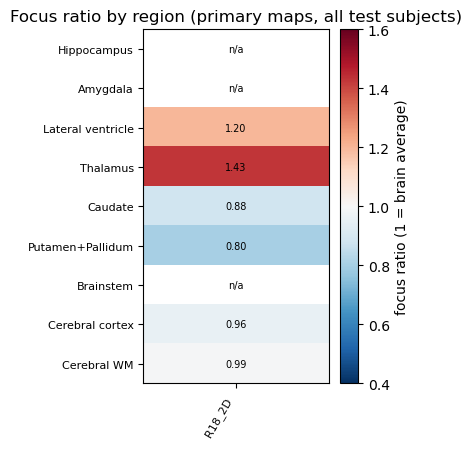

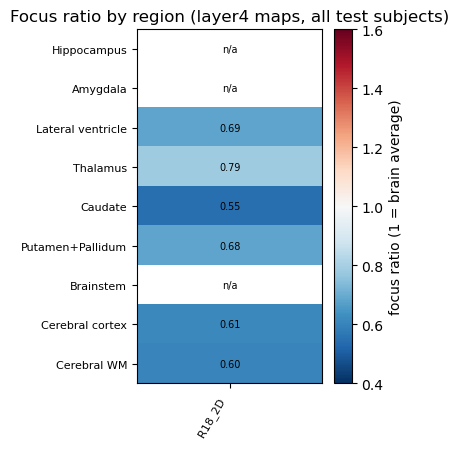

สรุป Grad-CAM (ชุดทดสอบ, mean ข้าม seed ต่อคน แล้วเฉลี่ยข้ามคน)

R18_2D gradcam/layer3/axial: ฮิปโปแคมปัส อัตราโฟกัส nan (AD nan | Normal nan | p=nan) n=0

หมายเหตุ: อัตราโฟกัส 1 = เท่าค่าเฉลี่ยทั้งสมอง n/a = บริเวณนั้นไม่อยู่บนภาพที่โมเดลเห็น
ค่า p เป็นการดูเชิงสำรวจ (Mann-Whitney, 36 คน, ไม่ปรับหลายการทดสอบ) ห้ามอ้างเป็นนัยสำคัญทางสถิติ
แผนที่ของ ResNet ที่ชั้นลึกหยาบ (layer4 = 4x4 ช่องบนภาพ 128 พิกเซล) ไม่ใช่ตำแหน่งแม่นยำ

ไฟล์ทั้งหมดอยู่ที่ /home/jovyan/Alzheimer's/src/Model/2D/Resnet18/gradcam_output


In [16]:
from scipy.stats import mannwhitneyu
frames = []
for g in GROUPS:
    p = os.path.join(OUT_DIR, f"{g['key']}_roi.csv")
    if os.path.exists(p):
        frames.append(pd.read_csv(p))
assert frames, "ยังไม่มีผลของโมเดลใด"
D = pd.concat(frames)
subj = D.groupby(["group", "method", "layer", "plane", "roi", "sid", "label"], as_index=False)["ratio"].mean()   # เฉลี่ยข้าม seed ต่อคน
rows = []
for (grp, method, layer, plane, roi), s in subj.groupby(["group", "method", "layer", "plane", "roi"]):
    a, n_ = s[s.label == 1]["ratio"].dropna(), s[s.label == 0]["ratio"].dropna()
    p = mannwhitneyu(a, n_).pvalue if len(a) >= 3 and len(n_) >= 3 else np.nan
    rows.append(dict(group=grp, method=method, layer=layer, plane=plane, roi=roi, n_subjects=int(s["ratio"].notna().sum()),
                     ratio_all=s["ratio"].mean(), ratio_AD=a.mean() if len(a) else np.nan, ratio_Normal=n_.mean() if len(n_) else np.nan,
                     p_AD_vs_Normal=p))
S = pd.DataFrame(rows)
S.to_csv(os.path.join(OUT_DIR, "gradcam_roi_summary.csv"), index=False)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 20)
display(S[S.roi == "Hippocampus"].round(3))

# แผนที่ความร้อน: บริเวณ x (โมเดล, แผนที่) ของคนทั้งชุดทดสอบ
for layer_key, lay in (("primary", list(PRIMARY_LAYERS) + ["input"]), ("layer4", ["layer4"])):
    sub = S[S.layer.isin(lay)].copy()
    if sub.empty: continue
    sub["col"] = sub["group"] + " " + sub["plane"].where(sub["method"] == "gradxinput", "")
    piv = sub.pivot_table(index="roi", columns="col", values="ratio_all").reindex(list(ROI_LABELS))
    fig, ax = plt.subplots(figsize=(1.0 * piv.shape[1] + 3, 4.6))
    im = ax.imshow(piv.values, cmap="RdBu_r", vmin=0.4, vmax=1.6, aspect="auto")
    ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels(piv.index, fontsize=8)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            v = piv.values[i, j]
            ax.text(j, i, "n/a" if np.isnan(v) else f"{v:.2f}", ha="center", va="center", fontsize=7)
    plt.colorbar(im, label="focus ratio (1 = brain average)"); ax.set_title(f"Focus ratio by region ({layer_key} maps, all test subjects)")
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"gradcam_heatmap_{layer_key}.png"), dpi=140); plt.show()

# สัดส่วนระนาบที่ 2.5D ใช้
sh = [pd.read_csv(os.path.join(OUT_DIR, f"{g['key']}_plane_share.csv")) for g in GROUPS if os.path.exists(os.path.join(OUT_DIR, f"{g['key']}_plane_share.csv"))]
if sh:
    SH = pd.concat(sh).groupby(["group", "plane"])["share"].agg(["mean", "std"]).round(3)
    display(SH); SH.to_csv(os.path.join(OUT_DIR, "gradcam_plane_share.csv"))

lines = ["สรุป Grad-CAM (ชุดทดสอบ, mean ข้าม seed ต่อคน แล้วเฉลี่ยข้ามคน)", ""]
for grp in S["group"].unique():
    h = S[(S.group == grp) & (S.roi == "Hippocampus") & (S.layer.isin(list(PRIMARY_LAYERS) + ["input"]))]
    for _, r in h.iterrows():
        lines.append(f"{grp} {r.method}/{r.layer}/{r.plane}: ฮิปโปแคมปัส อัตราโฟกัส {r.ratio_all:.2f} (AD {r.ratio_AD:.2f} | Normal {r.ratio_Normal:.2f} | p={r.p_AD_vs_Normal:.3f}) n={r.n_subjects}")
lines += ["", "หมายเหตุ: อัตราโฟกัส 1 = เท่าค่าเฉลี่ยทั้งสมอง n/a = บริเวณนั้นไม่อยู่บนภาพที่โมเดลเห็น",
          "ค่า p เป็นการดูเชิงสำรวจ (Mann-Whitney, 36 คน, ไม่ปรับหลายการทดสอบ) ห้ามอ้างเป็นนัยสำคัญทางสถิติ",
          "แผนที่ของ ResNet ที่ชั้นลึกหยาบ (layer4 = 4x4 ช่องบนภาพ 128 พิกเซล) ไม่ใช่ตำแหน่งแม่นยำ"]
open(os.path.join(OUT_DIR, "gradcam_summary.txt"), "w", encoding="utf-8").write("\n".join(lines))
print("\n".join(lines)); print("\nไฟล์ทั้งหมดอยู่ที่", OUT_DIR)
